# Combined analysis: crop fires and Delhi PM2.5

This notebook joins the fire data and the pollution data.
It answers the questions that need both.
Is the fire link to PM2.5 real? How fast does smoke arrive? Is PM2.5 higher on high fire days? How much do fires add in November?
Every model uses the same walk-forward split. Rows are never shuffled.

## 1. Setup and data

We load the daily files from both halves.
Run the individual notebooks first, so the files in `data/processed` exist.
All random choices use seed 42.
Figures are saved in `figures/combined`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE, mutual_info_regression
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

ROOT = Path(".") if Path("data").exists() else Path("..")
DATA = ROOT / "data/processed"
FIG = ROOT / "figures/combined"
FIG.mkdir(parents=True, exist_ok=True)

LIMIT = 60
PM_LABEL = "PM2.5 (µg/m³)"
AQI_BINS = [-np.inf, 30, 60, 90, 120, 250, np.inf]
AQI_LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
LEVELS = ["low", "medium", "high"]
SEASONS = ["Pre-monsoon", "Monsoon", "Post-monsoon"]
MONTHS = ["Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]

### Helper functions

These small functions are used again and again below.
The walk-forward function trains on the past and tests on the next block of days.
The two baselines use the same loop, so the scores are fair.

In [2]:
def load_daily(name):
    """Read a processed daily file and index it by date."""
    try:
        return pd.read_csv(DATA / name, parse_dates=["date"]).set_index("date")
    except FileNotFoundError:
        raise FileNotFoundError(f"{name} is missing. Run the individual notebooks first.")


def season_of(month):
    if month in (3, 4, 5, 6):
        return "Pre-monsoon"
    return "Monsoon" if month in (7, 8, 9) else "Post-monsoon"


def save_fig(name):
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")


def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}


class TrainMean:
    """Baseline: predict the mean PM2.5 of the training days."""
    def fit(self, X, y_log):
        self.level = np.log1p(np.expm1(y_log).mean())
        return self

    def predict(self, X):
        return np.full(len(X), self.level)


class Persistence:
    """Baseline: today equals yesterday."""
    def fit(self, X, y_log):
        return self

    def predict(self, X):
        return np.log1p(X["pm25_lag1"].to_numpy())


def walk_forward(make_model, X, y, n_splits=5):
    """Same walk-forward loop for every model. Rows are never shuffled."""
    folds = []
    oof = pd.Series(np.nan, index=y.index)
    for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(X), start=1):
        model = make_model()
        model.fit(X.iloc[tr], np.log1p(y.iloc[tr]))
        pred = np.clip(np.expm1(model.predict(X.iloc[te])), 0, None)
        oof.iloc[te] = pred
        folds.append({"fold": k, "train_days": len(tr), "test_days": len(te),
                      "first_test_day": y.index[te[0]].date(), **score(y.iloc[te], pred)})
    return pd.DataFrame(folds), oof

In [3]:
topic = load_daily("topicA_daily.csv")
fires = load_daily("fires_daily.csv")
pollution = load_daily("pollution_features.csv")
festivals = load_daily("festival_calendar.csv")
fire_points = pd.read_csv(DATA / "fires_clean.csv", parse_dates=["date"],
                          usecols=["date", "latitude", "longitude", "frp"])

extra = ["fire_central", "fire_count_prev3", "fire_count_prev7", "is_burning_season", "fire_level"]
daily = topic.join(fires[extra])
fire_cols = [c for c in daily.columns if c.startswith("fire_") and c != "fire_level"]
daily["aqi"] = pd.cut(daily["pm25"], AQI_BINS, labels=AQI_LABELS)
daily["season"] = daily.index.month.map(season_of)
daily["month_name"] = daily.index.month.map(lambda m: MONTHS[m - 3])

print("Topic A table:", topic.shape, "| fire table:", fires.shape, "| modelling table:", pollution.shape)

Topic A table: (275, 11) | fire table: (275, 12) | modelling table: (264, 17)


## 2. The merged table

We join the fire columns and the pollution columns on the date.
Then we check the result.

In [4]:
expected = pd.date_range("2025-03-01", "2025-11-30", freq="D")
checks = pd.Series({
    "rows": len(daily),
    "first date": daily.index.min().date(),
    "last date": daily.index.max().date(),
    "missing dates": len(expected.difference(daily.index)),
    "duplicate dates": int(daily.index.duplicated().sum()),
    "NaN in fire columns": int(daily[fire_cols].isna().sum().sum()),
    "zero-fire days (filled with 0)": int((daily["fire_count"] == 0).sum()),
    "days without PM2.5": int(daily["pm25"].isna().sum()),
})
assert checks["rows"] == 275 and checks["missing dates"] == 0 and checks["NaN in fire columns"] == 0
assert np.allclose(topic[["fire_count", "fire_frp"]], fires[["fire_count", "fire_frp"]])
checks

rows                                     275
first date                        2025-03-01
last date                         2025-11-30
missing dates                              0
duplicate dates                            0
NaN in fire columns                        0
zero-fire days (filled with 0)            44
days without PM2.5                         4
dtype: object

**What we see:** The table has 275 days, from 1 Mar to 30 Nov. No date is missing.
44 days have zero fires, and they carry 0, not NaN.
The plan said 33. That count used every detection type. We keep only vegetation fires, so more days are empty.
4 days have no PM2.5 reading: 10 Apr, 26 May, 2 Jun and 3 Jun.

A missing value matrix shows where data is absent.

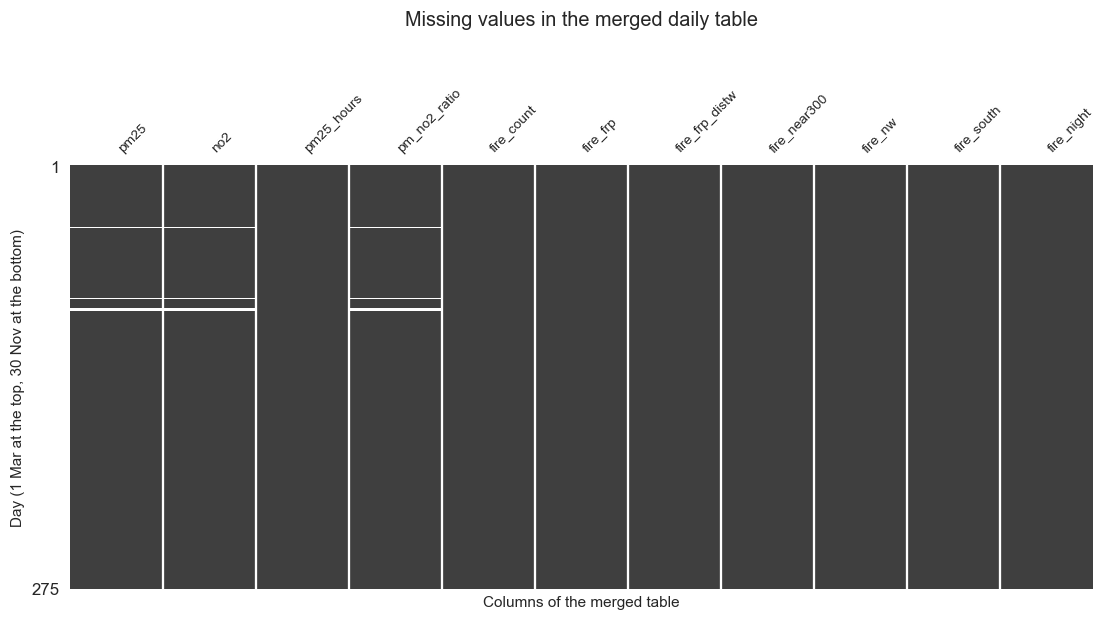

In [5]:
ax = msno.matrix(daily[topic.columns], figsize=(12, 5), fontsize=9, sparkline=False)
ax.set_title("Missing values in the merged daily table", fontsize=13, pad=40)
ax.set_xlabel("Columns of the merged table")
ax.set_ylabel("Day (1 Mar at the top, 30 Nov at the bottom)")
save_fig("merged_missingno.png")
plt.show()

**What we see:** Only PM2.5, NO2 and their ratio have gaps.
All three are missing on the same 4 days. The station was offline then.
The fire columns are complete.

## 3. Combined graphs

These graphs need both fire and pollution data.

### Daily PM2.5 and fire count

PM2.5 is the red line. Fire count is the blue bars on the right axis.

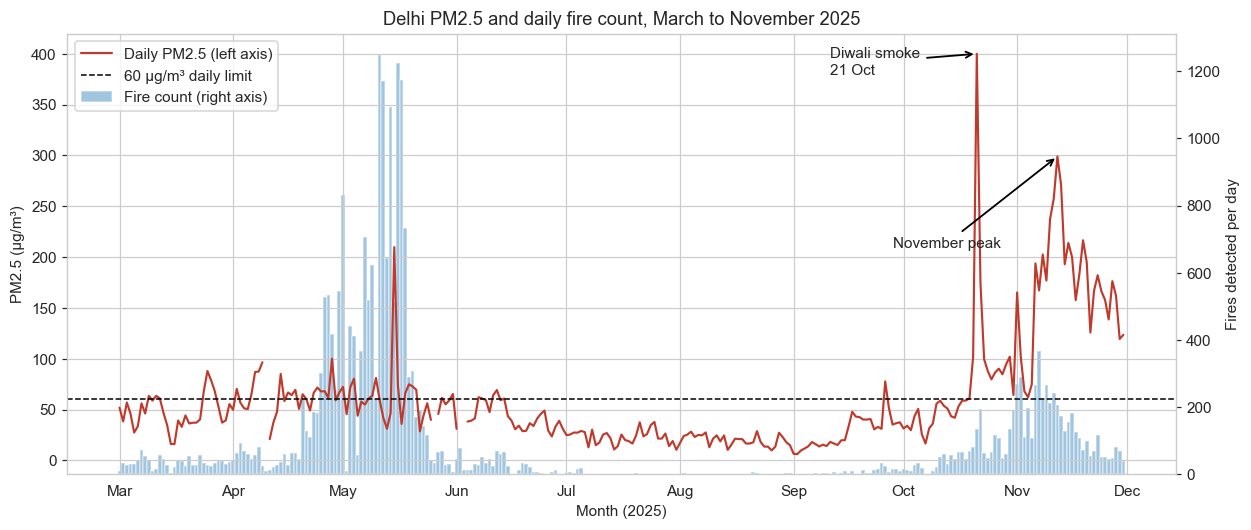

Diwali (festival table): 2025-10-20 | highest PM2.5 near Diwali: 2025-10-21 399.9 | November peak: 2025-11-12 298.9


In [6]:
diwali = festivals.index[festivals["festival"].fillna("").eq("Diwali")][0]
window = daily.loc[diwali - pd.Timedelta(days=1): diwali + pd.Timedelta(days=3), "pm25"]
smoke_day = window.idxmax()
nov_peak = daily.loc[daily.index.month == 11, "pm25"].idxmax()

fig, ax1 = plt.subplots(figsize=(13, 5.2))
ax2 = ax1.twinx()
ax2.bar(daily.index, daily["fire_count"], width=1.0, color="#2c7fb8", alpha=0.45, label="Fire count (right axis)")
ax2.set_ylabel("Fires detected per day")
ax2.grid(False)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.plot(daily.index, daily["pm25"], color="#c0392b", lw=1.4, label="Daily PM2.5 (left axis)")
ax1.axhline(LIMIT, color="black", ls="--", lw=1, label="60 µg/m³ daily limit")
ax1.set_ylabel(PM_LABEL)
ax1.set_xlabel("Month (2025)")
ax1.annotate("Diwali smoke\n21 Oct", xy=(smoke_day, daily.loc[smoke_day, "pm25"]),
             xytext=(smoke_day - pd.Timedelta(days=40), daily.loc[smoke_day, "pm25"] * 0.95),
             arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10)
ax1.annotate("November peak", xy=(nov_peak, daily.loc[nov_peak, "pm25"]),
             xytext=(nov_peak - pd.Timedelta(days=45), daily.loc[nov_peak, "pm25"] * 0.7),
             arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10)
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Delhi PM2.5 and daily fire count, March to November 2025")
save_fig("timeline_pm25_fires.png")
plt.show()
print("Diwali (festival table):", diwali.date(), "| highest PM2.5 near Diwali:", smoke_day.date(),
      round(daily.loc[smoke_day, "pm25"], 1), "| November peak:", nov_peak.date(), round(daily.loc[nov_peak, "pm25"], 1))

**What we see:** Fires come in two seasons.
The wheat season peaks in May, with up to 1,249 fires in one day. PM2.5 stays near 60 then.
The paddy season in November has fewer fires per day (148 on average, against 435 in May). But PM2.5 is much higher (172, against 62).
The biggest spike is 399.9 on 21 Oct, the day after Diwali. Firecracker smoke is the likely cause, not fires.

### Dashboard with a fire dropdown

Three panels share one date axis. Use the dropdown to change the fire measure.

In [7]:
metrics = ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300", "fire_night"]
labels = {"fire_count": "Fire count", "fire_frp": "Total FRP (MW)", "fire_frp_distw": "Distance-weighted FRP",
          "fire_near300": "Fires within 300 km", "fire_night": "Night-time fires"}

dash = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                     subplot_titles=("Daily PM2.5", "Daily NO2", "Fire activity (use the dropdown)"))
dash.add_trace(go.Scatter(x=daily.index, y=daily["pm25"], name="PM2.5", line=dict(color="#c0392b")), row=1, col=1)
dash.add_hline(y=LIMIT, line_dash="dash", line_color="black", row=1, col=1)
dash.add_trace(go.Scatter(x=daily.index, y=daily["no2"], name="NO2", line=dict(color="#6a3d9a")), row=2, col=1)
for i, m in enumerate(metrics):
    dash.add_trace(go.Bar(x=daily.index, y=daily[m], name=labels[m], marker_color="#2c7fb8", visible=(i == 0)), row=3, col=1)

buttons = [dict(label=labels[m], method="update",
                args=[{"visible": [True, True] + [j == i for j in range(len(metrics))]},
                      {"yaxis3.title.text": labels[m]}]) for i, m in enumerate(metrics)]
dash.update_layout(updatemenus=[dict(buttons=buttons, x=1.0, y=1.12, xanchor="right")],
                   height=720, showlegend=False, title_text="PM2.5, NO2 and fires on one date axis")
dash.update_yaxes(title_text="PM2.5 (µg/m³)", row=1, col=1)
dash.update_yaxes(title_text="NO2 (ppb)", row=2, col=1)
dash.update_yaxes(title_text=labels[metrics[0]], row=3, col=1)
dash.update_xaxes(title_text="Date", row=3, col=1)
dash.show()

**What we see:** All five fire measures follow the same two seasons.
NO2 rises less than PM2.5 does in the burning seasons.

### Animated map of daily fires

Press play. Each dot is a fire. The colour shows FRP, the heat of the fire. The star is Delhi.
The title shows that day's PM2.5.

In [8]:
by_day = {d: g for d, g in fire_points.groupby("date")}


def frame_title(d):
    n = len(by_day[d]) if d in by_day else 0
    pm = daily.loc[d, "pm25"]
    pm_text = "no reading" if pd.isna(pm) else f"{pm:.0f} µg/m³"
    return f"{d:%d %b %Y} | Delhi PM2.5: {pm_text} | fires: {n}"


def frame_marker(d):
    g = by_day.get(d)
    if g is None:
        return dict(lat=[], lon=[], marker=dict(color=[], size=5))
    return dict(lat=g["latitude"].round(3).tolist(), lon=g["longitude"].round(3).tolist(),
                marker=dict(color=g["frp"].round(1).tolist(), size=5))


days = list(daily.index)
first = frame_marker(days[0])
anim = go.Figure(
    data=[go.Scattergeo(lat=first["lat"], lon=first["lon"], mode="markers",
                        marker=dict(color=first["marker"]["color"], size=5, colorscale="YlOrRd", cmin=0, cmax=30,
                                    colorbar=dict(title="FRP (MW)")), name="Fires"),
          go.Scattergeo(lat=[28.53], lon=[77.19], mode="markers+text", text=["Delhi"], textposition="top right",
                        marker=dict(symbol="star", size=14, color="black"), name="Delhi")],
    frames=[go.Frame(name=str(d.date()), traces=[0],
                     data=[go.Scattergeo(lat=frame_marker(d)["lat"], lon=frame_marker(d)["lon"], mode="markers",
                                         marker=frame_marker(d)["marker"])],
                     layout=go.Layout(title_text=frame_title(d))) for d in days])
anim.update_layout(
    title_text=frame_title(days[0]), height=620,
    geo=dict(lonaxis_range=[73.5, 79.5], lataxis_range=[26.5, 31.5], showland=True, landcolor="#f4f1ea",
             showcountries=True, showsubunits=True, resolution=50),
    updatemenus=[dict(type="buttons", showactive=False, x=0.05, y=-0.02,
                      buttons=[dict(label="Play", method="animate",
                                    args=[None, dict(frame=dict(duration=120, redraw=True), fromcurrent=True)]),
                               dict(label="Pause", method="animate",
                                    args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False))])])],
    sliders=[dict(currentvalue=dict(prefix="Day: "), pad=dict(t=30),
                  steps=[dict(method="animate", label=f"{d:%d %b}",
                              args=[[str(d.date())], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
                         for d in days])])
anim.show()

**What we see:** The map is almost empty in July and August.
Fires return in October.
Watch the title. PM2.5 climbs as the map fills up in late October and November.

### Fire count against PM2.5

Both axes use a log scale. The second plot splits the same data by season.

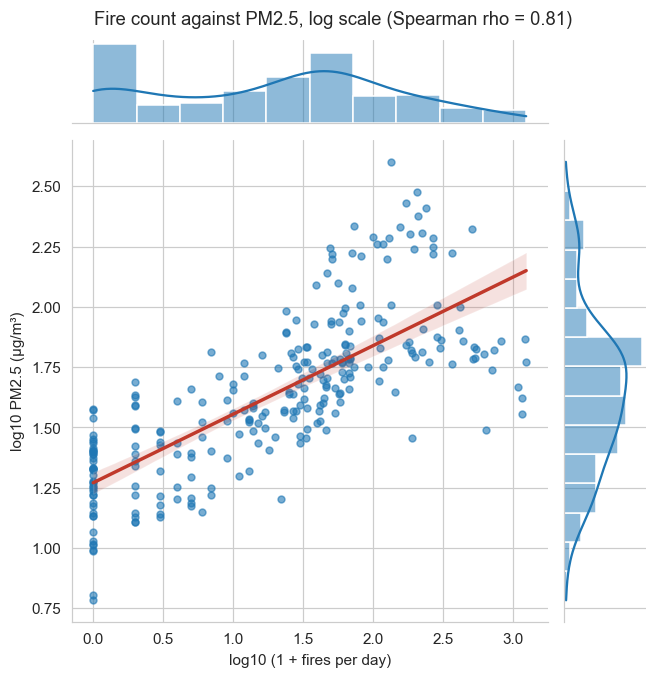

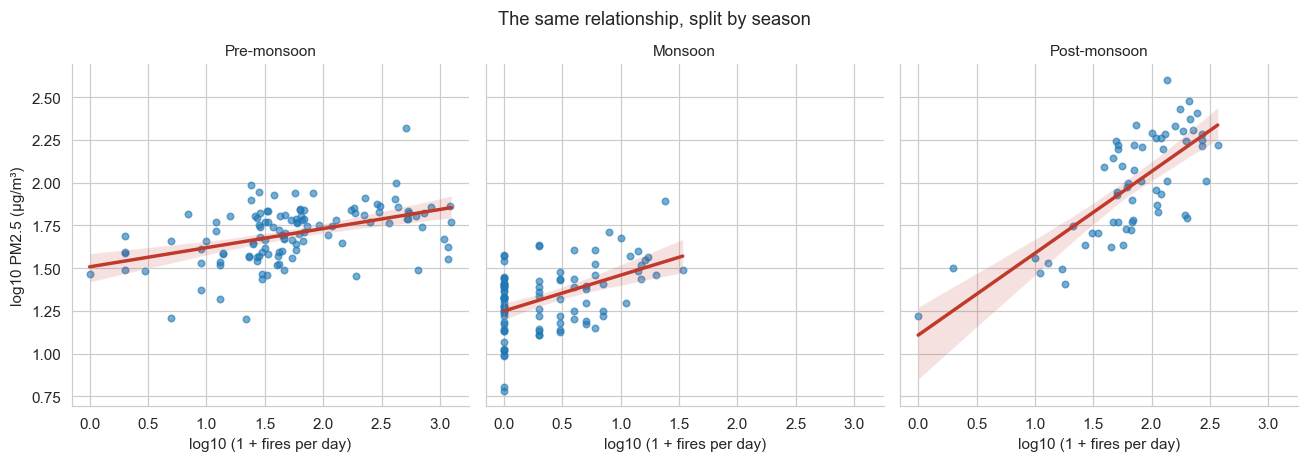

,days,spearman rho,p-value
season,,,
Pre-monsoon,118,0.48,5.3e-08
Monsoon,92,0.40,8.6e-05
Post-monsoon,61,0.73,3.6e-11


In [9]:
plot_df = daily.dropna(subset=["pm25"]).copy()
plot_df["log_fires"] = np.log10(1 + plot_df["fire_count"])
plot_df["log_pm25"] = np.log10(plot_df["pm25"])

rho, p = stats.spearmanr(plot_df["fire_count"], plot_df["pm25"])
jp = sns.jointplot(data=plot_df, x="log_fires", y="log_pm25", kind="reg", height=6,
                   scatter_kws=dict(s=20, alpha=0.6), line_kws=dict(color="#c0392b"))
jp.set_axis_labels("log10 (1 + fires per day)", "log10 PM2.5 (µg/m³)")
jp.figure.suptitle(f"Fire count against PM2.5, log scale (Spearman rho = {rho:.2f})", y=1.02)
save_fig("joint_fires_pm25.png")
plt.show()

fg = sns.FacetGrid(plot_df, col="season", col_order=SEASONS, height=4, sharex=True, sharey=True)
fg.map_dataframe(sns.regplot, x="log_fires", y="log_pm25", scatter_kws=dict(s=18, alpha=0.6),
                 line_kws=dict(color="#c0392b"))
fg.set_axis_labels("log10 (1 + fires per day)", "log10 PM2.5 (µg/m³)")
fg.set_titles("{col_name}")
fg.figure.suptitle("The same relationship, split by season", y=1.04)
save_fig("facet_fires_pm25_by_season.png")
plt.show()

season_rho = plot_df.groupby("season").apply(lambda g: pd.Series({
    "days": len(g), "spearman rho": stats.spearmanr(g["fire_count"], g["pm25"])[0],
    "p-value": stats.spearmanr(g["fire_count"], g["pm25"])[1]})).reindex(SEASONS)
season_rho_view = season_rho.copy()
season_rho_view["days"] = season_rho_view["days"].astype(int)
season_rho_view["spearman rho"] = season_rho_view["spearman rho"].round(2)
season_rho_view["p-value"] = season_rho_view["p-value"].map(lambda p: f"{p:.1e}")
season_rho_view

**What we see:** More fires go with higher PM2.5 in every season.
The link is weakest in the monsoon (rho 0.40) and strongest after it (0.73).
One line over the whole year mixes the seasons. So the season plots are fairer.

### Pairplot by AQI category

Each dot is a day. The colour is the AQI category.

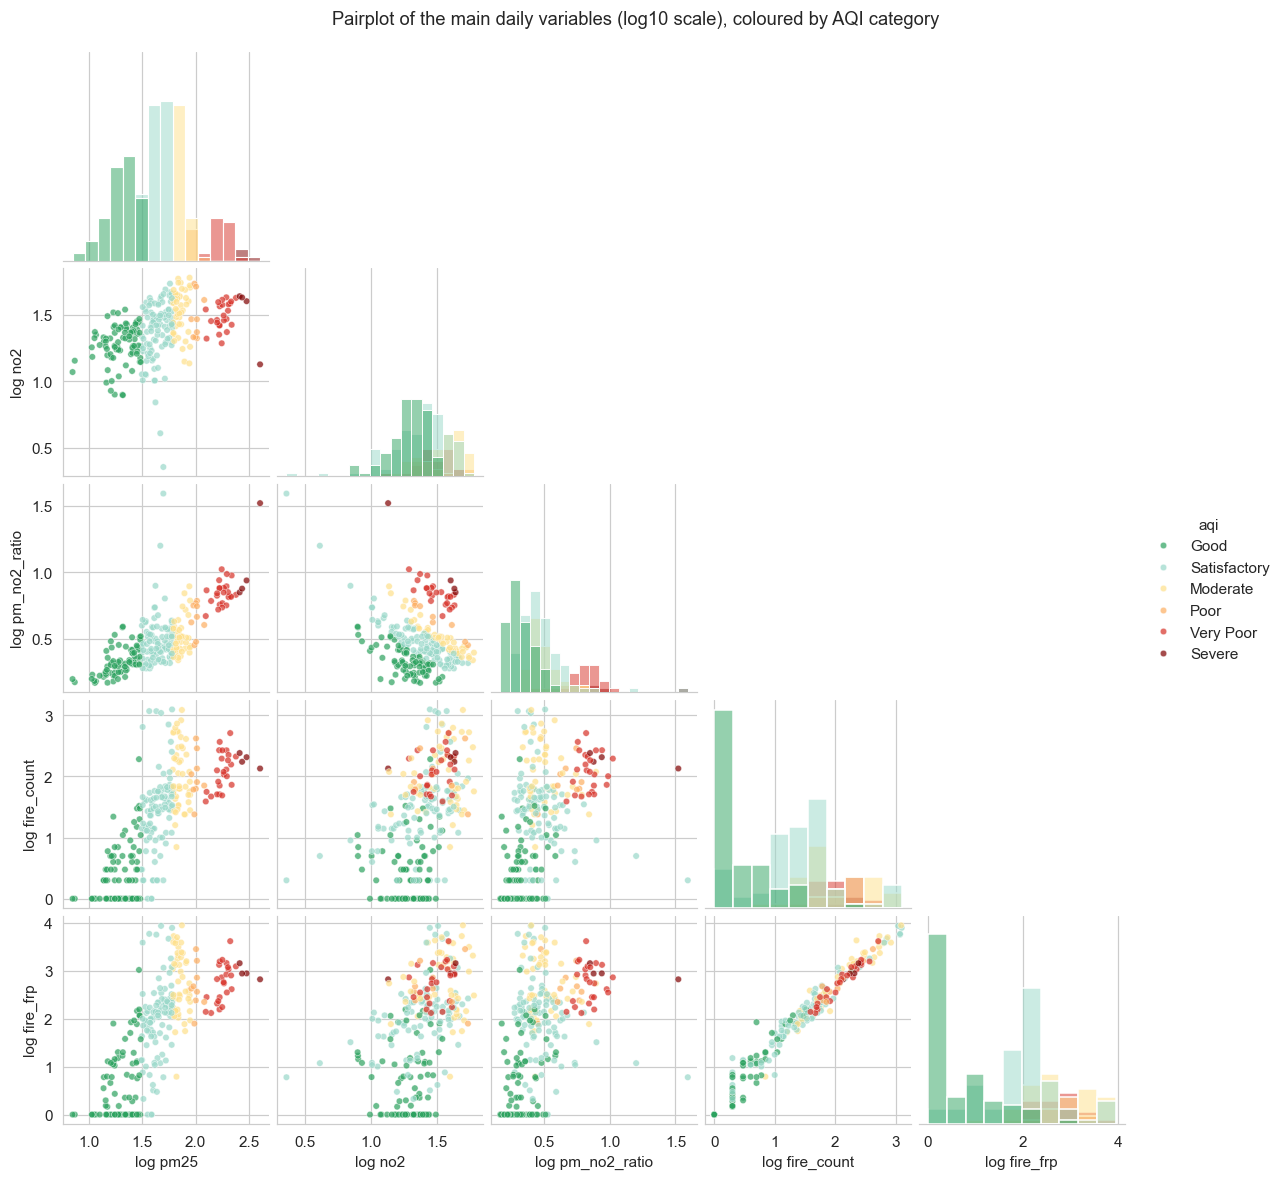

In [10]:
pair_df = plot_df[["pm25", "no2", "pm_no2_ratio", "fire_count", "fire_frp", "aqi"]].copy()
pair_df["aqi"] = pair_df["aqi"].astype(str)
for col in ["pm25", "no2", "pm_no2_ratio", "fire_count", "fire_frp"]:
    pair_df[f"log {col}"] = np.log10(1 + pair_df.pop(col))
palette = {"Good": "#2ca25f", "Satisfactory": "#99d8c9", "Moderate": "#fee08b", "Poor": "#fdae61",
           "Very Poor": "#d73027", "Severe": "#7f0000"}
palette = {k: v for k, v in palette.items() if k in set(pair_df["aqi"])}
pg = sns.pairplot(pair_df, hue="aqi", hue_order=list(palette), palette=palette, corner=True,
                  diag_kind="hist", plot_kws=dict(s=18, alpha=0.7), height=2.1)
pg.figure.suptitle("Pairplot of the main daily variables (log10 scale), coloured by AQI category", y=1.02)
save_fig("pairplot_aqi.png")
plt.show()

**What we see:** Very Poor and Severe days nearly always have many fires. The lowest count was 38.
Fire count and FRP form almost a straight line. They carry the same information.
PM2.5 and NO2 rise together, but NO2 separates the categories less well.

### Spearman clustermap

The map groups variables that move together.

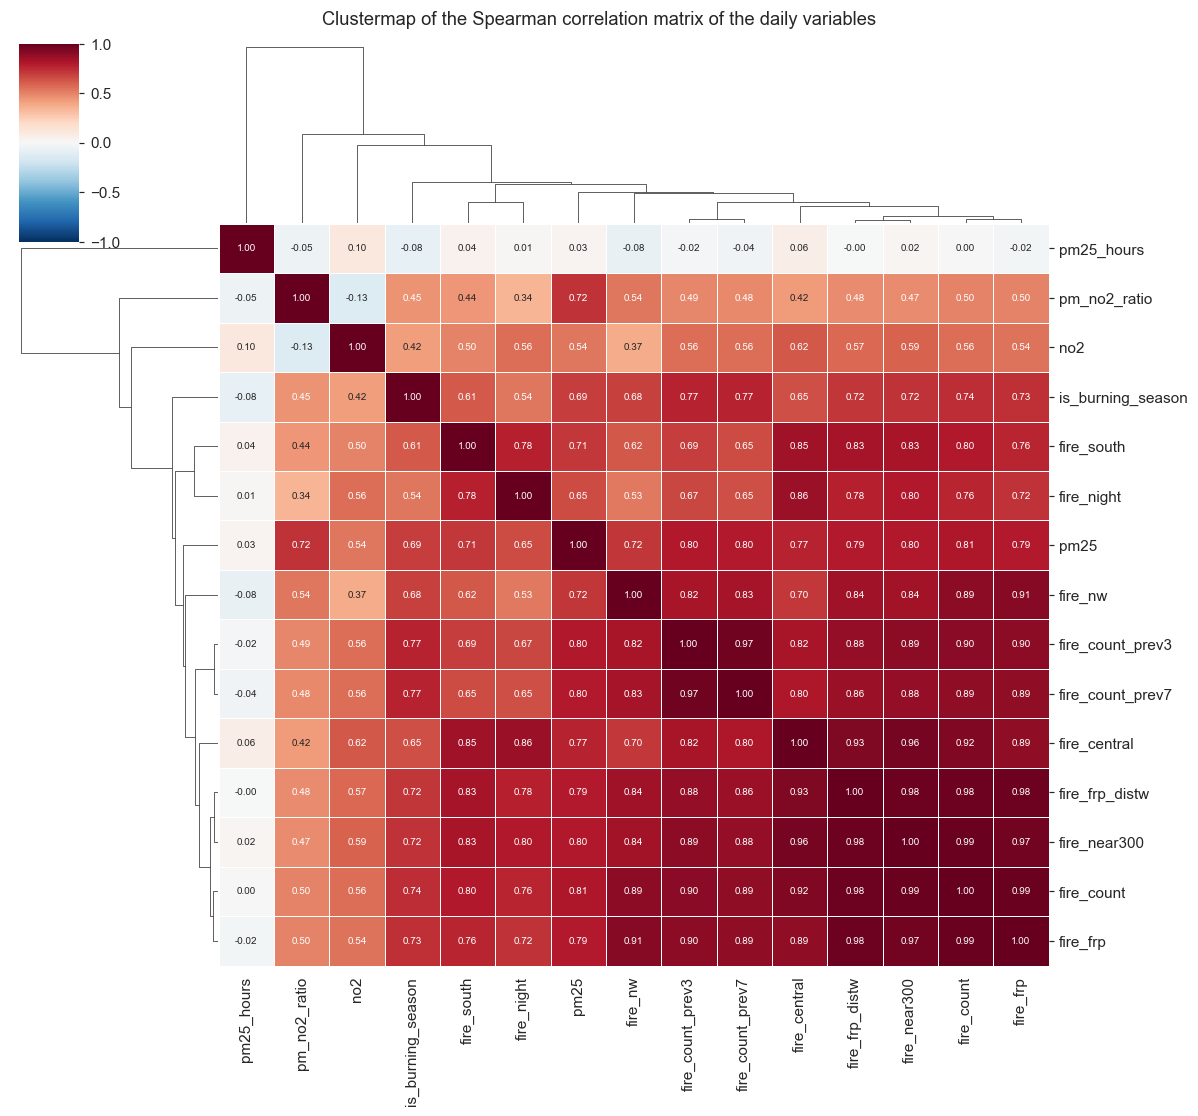

fire_count           0.81
fire_near300         0.80
fire_count_prev3     0.80
fire_count_prev7     0.80
fire_frp             0.79
fire_frp_distw       0.79
fire_central         0.77
pm_no2_ratio         0.72
fire_nw              0.72
fire_south           0.71
is_burning_season    0.69
fire_night           0.65
no2                  0.54
pm25_hours           0.03
Name: pm25, dtype: float64

In [11]:
corr_cols = ["pm25", "no2", "pm25_hours", "pm_no2_ratio"] + fire_cols + ["is_burning_season"]
spearman = daily[corr_cols].corr(method="spearman")
cm = sns.clustermap(spearman, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
                    annot_kws={"size": 6.5}, figsize=(11, 10), linewidths=0.4)
cm.figure.suptitle("Clustermap of the Spearman correlation matrix of the daily variables", y=1.01)
save_fig("clustermap_spearman.png")
plt.show()
spearman["pm25"].drop("pm25").sort_values(ascending=False).round(2)

**What we see:** The main fire columns form one tight block, mostly above 0.85.
PM2.5 correlates 0.81 with fire count and 0.54 with NO2. The ratio correlates 0.72.
`pm25_hours` links to nothing. That is what we want.

### PM2.5 to NO2 ratio against fires

A high ratio means extra particles without extra traffic.

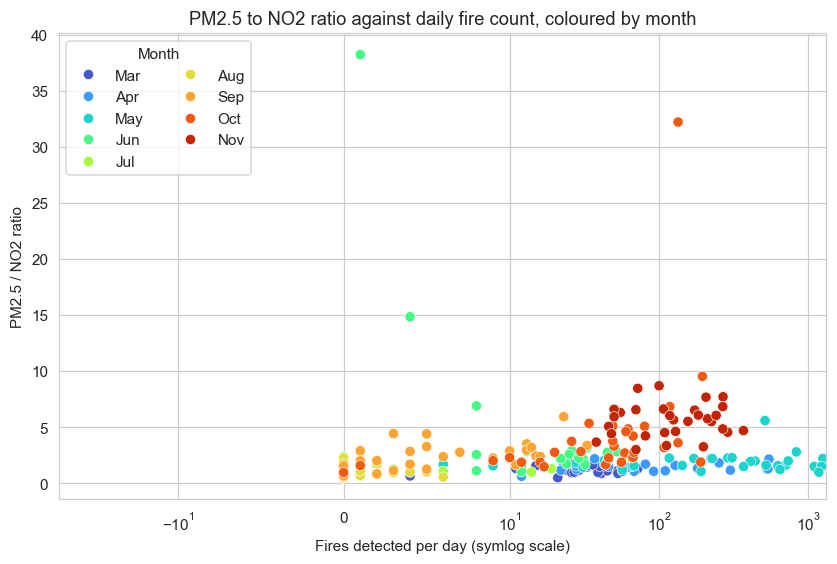

,pm_no2_ratio,fire_count
month_name,,
Mar,1.3,33.7
Apr,1.6,148.1
May,1.9,448.3
Jun,4.0,22.9
Jul,1.1,1.9
Aug,1.1,1.1
Sep,2.3,6.9
Oct,4.2,60.5
Nov,5.6,147.6


In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=plot_df, x="fire_count", y="pm_no2_ratio", hue="month_name", hue_order=MONTHS,
                palette="turbo", s=45, edgecolor="white", linewidth=0.4, ax=ax)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlabel("Fires detected per day (symlog scale)")
ax.set_ylabel("PM2.5 / NO2 ratio")
ax.set_title("PM2.5 to NO2 ratio against daily fire count, coloured by month")
ax.legend(title="Month", ncol=2)
save_fig("ratio_vs_fires.png")
plt.show()
plot_df.groupby("month_name")[["pm_no2_ratio", "fire_count"]].mean().reindex(MONTHS).round(1)

**What we see:** The ratio is lowest in July and August (1.1). It is highest in November (5.6).
June is also high (4.0), with few fires (23 a day). June is probably dust, but we did not test that.
October and November fit smoke.

### PM2.5 by fire level

Fire level is low, medium or high. Each level holds a third of the days.
The dashed line is the 60 µg/m³ limit.

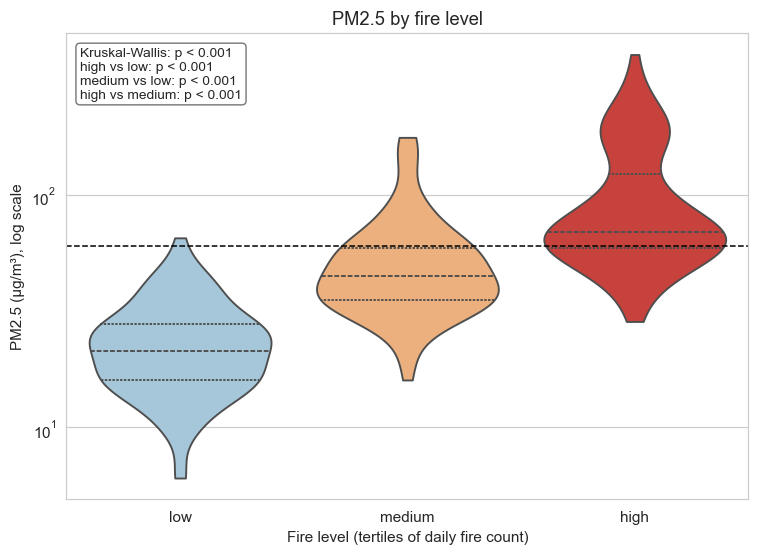

,count,median,mean
fire_level,,,
low,94,21.4,23.5
medium,86,44.8,53.0
high,91,69.4,101.5


In [13]:
violin_df = plot_df.copy()
violin_df["fire_level"] = pd.Categorical(violin_df["fire_level"], LEVELS, ordered=True)
g_low, g_med, g_high = [violin_df.loc[violin_df["fire_level"] == lv, "pm25"] for lv in LEVELS]
p_hl = stats.mannwhitneyu(g_high, g_low).pvalue
p_ml = stats.mannwhitneyu(g_med, g_low).pvalue
p_hm = stats.mannwhitneyu(g_high, g_med).pvalue
p_kw = stats.kruskal(g_low, g_med, g_high).pvalue


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


fig, ax = plt.subplots(figsize=(8, 5.5))
sns.violinplot(data=violin_df, x="fire_level", y="pm25", order=LEVELS, cut=0, inner="quart",
               palette=["#9ecae1", "#fdae6b", "#de2d26"], log_scale=True, ax=ax)
ax.axhline(LIMIT, color="black", ls="--", lw=1)
ax.set_xlabel("Fire level (tertiles of daily fire count)")
ax.set_ylabel(PM_LABEL + ", log scale")
ax.set_title("PM2.5 by fire level")
ax.text(0.02, 0.97, f"Kruskal-Wallis: {fmt_p(p_kw)}\nhigh vs low: {fmt_p(p_hl)}\nmedium vs low: {fmt_p(p_ml)}\nhigh vs medium: {fmt_p(p_hm)}",
        transform=ax.transAxes, va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="grey"))
save_fig("violin_pm25_fire_level.png")
plt.show()
violin_df.groupby("fire_level", observed=True)["pm25"].agg(["count", "median", "mean"]).round(1)

**What we see:** Median PM2.5 is 21 on low fire days, 45 on medium days and 69 on high days.
Every pair differs (p < 0.001).
The high group sits above the limit at the median.

## 4. How fast does smoke arrive?

We correlate fire count with PM2.5 for October and November.
The fire series is shifted by 0 to 5 days. We use Spearman because fire counts are skewed.

Both series climb through these two months. That can fake a lag effect.
So we also remove a 15-day rolling mean from both series.
This is only for the plot. Model features never use it.

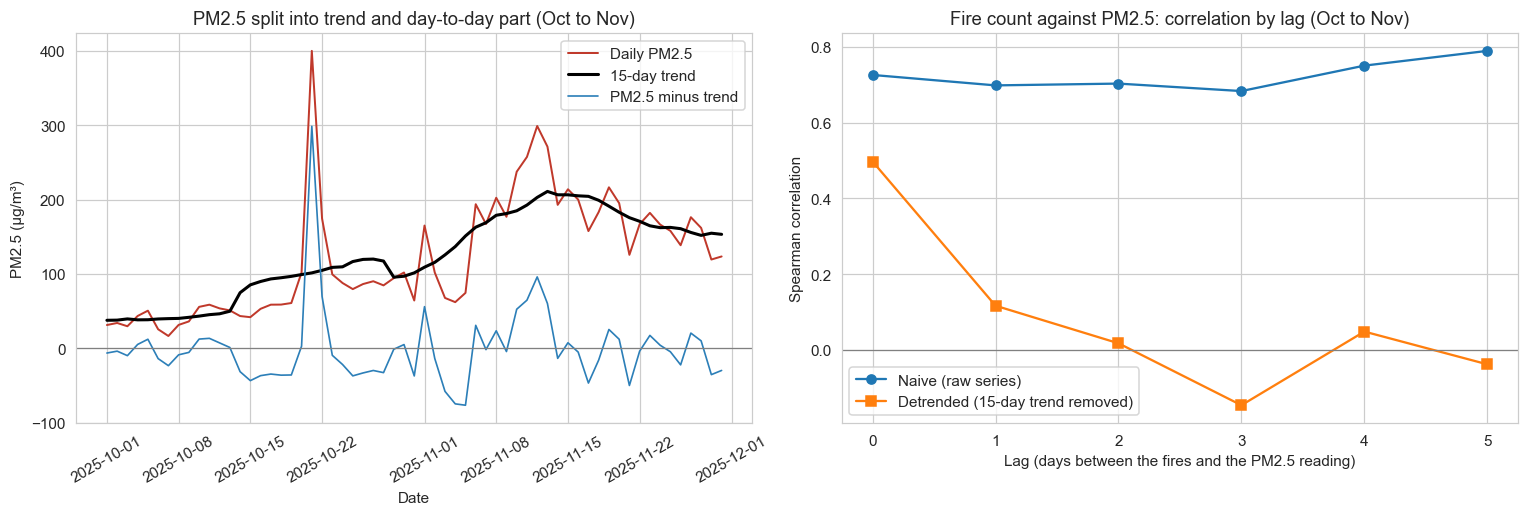

,naive rho,detrended rho,detrended p
lag (days),,,
0,0.726,0.497,0.000
1,0.698,0.117,0.370
2,0.703,0.018,0.892
3,0.683,-0.146,0.262
4,0.750,0.049,0.710
5,0.789,-0.038,0.772


In [14]:
def detrend(s, window=15):
    """Remove a centred rolling mean. Fine for plots, never used for model features."""
    return s - s.rolling(window, center=True, min_periods=5).mean()


def lag_corr(x, y, lags=range(0, 6), mask=None):
    rows = []
    for k in lags:
        pair = pd.concat([x.shift(k), y], axis=1, keys=["x", "y"])
        if mask is not None:
            pair = pair[mask]
        pair = pair.dropna()
        rho, p = stats.spearmanr(pair["x"], pair["y"])
        rows.append({"lag (days)": k, "rho": rho, "p": p, "n": len(pair)})
    return pd.DataFrame(rows).set_index("lag (days)")


oct_nov = daily.index.month.isin([10, 11])
pm = daily["pm25"]
naive = lag_corr(daily["fire_count"], pm, mask=oct_nov)
flat = lag_corr(detrend(daily["fire_count"]), detrend(pm), mask=oct_nov)
lag_summary = pd.DataFrame({"naive rho": naive["rho"], "detrended rho": flat["rho"], "detrended p": flat["p"]})

trend = pm.rolling(15, center=True, min_periods=5).mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.plot(pm[oct_nov], color="#c0392b", lw=1.3, label="Daily PM2.5")
ax.plot(trend[oct_nov], color="black", lw=2, label="15-day trend")
ax.plot(detrend(pm)[oct_nov], color="#2c7fb8", lw=1.1, label="PM2.5 minus trend")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("PM2.5 split into trend and day-to-day part (Oct to Nov)")
ax.set_xlabel("Date")
ax.set_ylabel(PM_LABEL)
ax.tick_params(axis="x", rotation=30)
ax.legend()
ax = axes[1]
ax.plot(lag_summary.index, lag_summary["naive rho"], marker="o", label="Naive (raw series)")
ax.plot(lag_summary.index, lag_summary["detrended rho"], marker="s", label="Detrended (15-day trend removed)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Fire count against PM2.5: correlation by lag (Oct to Nov)")
ax.set_xlabel("Lag (days between the fires and the PM2.5 reading)")
ax.set_ylabel("Spearman correlation")
ax.legend()
fig.tight_layout()
save_fig("lag_naive_vs_detrended.png")
plt.show()
lag_summary.round(3)

**What we see:** The raw correlation is 0.73 at lag 0 and 0.79 at lag 5. It looks like smoke takes 5 days.
That is misleading. Both series share the same climb.
After detrending, the correlation is 0.50 at lag 0 and 0.12 at lag 1. After that it is near 0.
Lag 1 is not significant (p = 0.37).

**Verdict:** the smoke effect shows on the same day.
This fits fires that sit about 250 km from Delhi.

We repeat the detrended check for three fire measures.

In [15]:
feature_lags = pd.DataFrame({
    feat: lag_corr(detrend(daily[feat]), detrend(pm), lags=range(0, 4), mask=oct_nov)["rho"]
    for feat in ["fire_count", "fire_frp_distw", "fire_near300"]})
feature_lags.round(2)

,fire_count,fire_frp_distw,fire_near300
lag (days),,,
0,0.50,0.32,0.41
1,0.12,0.11,0.14
2,0.02,0.02,0.11
3,-0.15,-0.17,-0.05


**What we see:** Distance-weighted FRP (0.32) and fires within 300 km (0.41) do not beat plain fire count (0.50).
We keep the plain count.

## 5. Are high fire days more polluted?

We compare high fire days with low fire days.
High and low are the top and bottom third of days by fire count.
We run three tests.

In [16]:
valid = daily.dropna(subset=["pm25"]).copy()
low = valid.loc[valid["fire_level"] == "low", "pm25"]
high = valid.loc[valid["fire_level"] == "high", "pm25"]

mw = stats.mannwhitneyu(high, low, alternative="greater")
welch = stats.ttest_ind(np.log(high), np.log(low), equal_var=False, alternative="greater")

# check inside Oct-Nov only, so the season cannot explain the gap
on = valid[valid.index.month.isin([10, 11])]
cut = on["fire_count"].median()
on_high = on.loc[on["fire_count"] > cut, "pm25"]
on_low = on.loc[on["fire_count"] <= cut, "pm25"]
mw_on = stats.mannwhitneyu(on_high, on_low, alternative="greater")

tests = pd.DataFrame([
    {"test": "Mann-Whitney U, PM2.5, high vs low fire days", "statistic": mw.statistic, "p-value": mw.pvalue,
     "median high": high.median(), "median low": low.median()},
    {"test": "Welch t-test, log PM2.5, high vs low fire days", "statistic": welch.statistic, "p-value": welch.pvalue,
     "median high": high.median(), "median low": low.median()},
    {"test": "Mann-Whitney U, Oct to Nov only, above vs below median fires", "statistic": mw_on.statistic,
     "p-value": mw_on.pvalue, "median high": on_high.median(), "median low": on_low.median()},
]).set_index("test")
print(f"days: low n={len(low)}, high n={len(high)} | Oct-Nov split at {cut:.0f} fires: above n={len(on_high)}, below n={len(on_low)}")
tests_view = tests.copy()
tests_view["p-value"] = tests_view["p-value"].map(lambda p: f"{p:.1e}")
tests_view[["statistic", "median high", "median low"]] = tests_view[["statistic", "median high", "median low"]].round(1)
tests_view

days: low n=94, high n=91 | Oct-Nov split at 70 fires: above n=29, below n=32


,statistic,p-value,median high,median low
test,,,,
"Mann-Whitney U, PM2.5, high vs low fire days",8438.0,1.5e-30,69.4,21.4
"Welch t-test, log PM2.5, high vs low fire days",18.3,2.0e-42,69.4,21.4
"Mann-Whitney U, Oct to Nov only, above vs below median fires",819.0,1.5e-07,176.8,58.7


- **Mann-Whitney U** compares the groups without assuming a normal shape. PM2.5 is higher on high fire days (median 69, against 21). p < 0.001.
- **Welch t-test on log PM2.5.** The log makes the data closer to normal. The answer is the same. p < 0.001.
- **October and November only.** Days above the median fire count (70) have median PM2.5 of 177. Days at or below it have 59. p < 0.001. The season cannot explain this one.

Neighbouring days are not independent. So the p-values are too small.
The size of the gap matters more than the p-value.

Next we test AQI category against fire level.
Some categories have very few days. So we merge them into four groups.

In [17]:
ct_full = pd.crosstab(valid["aqi"], valid["fire_level"]).reindex(index=AQI_LABELS, columns=LEVELS, fill_value=0)
chi_full = stats.chi2_contingency(ct_full)
print("Full table, 6 AQI categories x 3 fire levels")
print(ct_full)
print(f"Cells with expected count below 5: {(chi_full[3] < 5).sum()} of {chi_full[3].size}")

groups = {"Good or Satisfactory": ["Good", "Satisfactory"], "Moderate": ["Moderate"],
          "Poor": ["Poor"], "Very Poor or Severe": ["Very Poor", "Severe"]}
ct = pd.DataFrame({name: ct_full.loc[cats].sum() for name, cats in groups.items()}).T[LEVELS]
chi = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi[0] / (ct.values.sum() * (min(ct.shape) - 1)))
print("\nMerged table, 4 AQI groups x 3 fire levels")
print(ct)
print(f"chi-square = {chi[0]:.1f}, dof = {chi[2]}, p = {chi[1]:.2e}, Cramer's V = {cramers_v:.2f}")
print(f"Cells with expected count below 5: {(chi[3] < 5).sum()} of {chi[3].size}")
(ct / ct.sum() * 100).round(1)

Full table, 6 AQI categories x 3 fire levels
fire_level    low  medium  high
aqi                            
Good           74      10     1
Satisfactory   19      55    24
Moderate        1      15    35
Poor            0       1     8
Very Poor       0       5    19
Severe          0       0     4
Cells with expected count below 5: 6 of 18

Merged table, 4 AQI groups x 3 fire levels
fire_level            low  medium  high
Good or Satisfactory   93      65    25
Moderate                1      15    35
Poor                    0       1     8
Very Poor or Severe     0       5    23
chi-square = 114.3, dof = 6, p = 2.59e-22, Cramer's V = 0.46
Cells with expected count below 5: 3 of 12


fire_level,low,medium,high
Good or Satisfactory,98.9,75.6,27.5
Moderate,1.1,17.4,38.5
Poor,0.0,1.2,8.8
Very Poor or Severe,0.0,5.8,25.3


**What we see:** On low fire days, 99% of days are Good or Satisfactory. On high fire days, only 28% are. And 25% are Very Poor or Severe.
Chi-square is 114.3 with 6 degrees of freedom. p < 0.001.
Cramer's V is 0.46. That is a moderate to strong link.
3 of 12 cells still have expected counts below 5. Treat the p-value as a rough guide.

## 6. Pollution regimes

We group days by how they look, not by the calendar.
We use PM2.5, NO2, the ratio and the fire columns.
Skewed columns use log(1 + x). Then we scale everything.
First we run PCA.

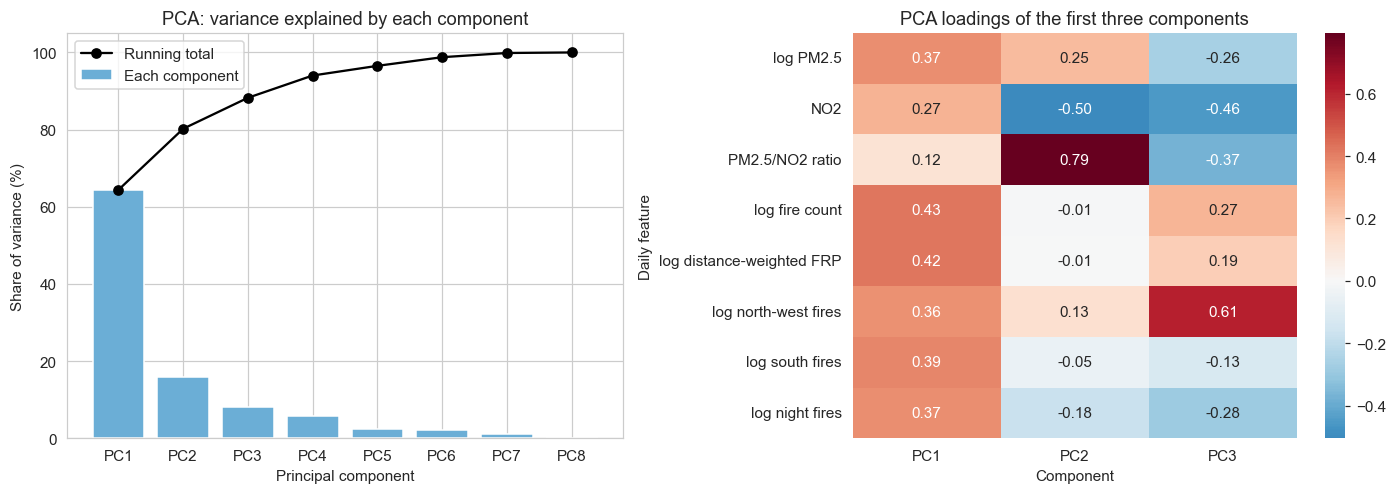

{'PC1': 64.4, 'PC2': 15.8, 'PC3': 8.0}


In [18]:
reg = daily.dropna(subset=["pm25", "no2"]).copy()
reg_features = pd.DataFrame({
    "log PM2.5": np.log1p(reg["pm25"]),
    "NO2": reg["no2"],
    "PM2.5/NO2 ratio": reg["pm_no2_ratio"],
    "log fire count": np.log1p(reg["fire_count"]),
    "log distance-weighted FRP": np.log1p(reg["fire_frp_distw"]),
    "log north-west fires": np.log1p(reg["fire_nw"]),
    "log south fires": np.log1p(reg["fire_south"]),
    "log night fires": np.log1p(reg["fire_night"]),
})
X_reg = StandardScaler().fit_transform(reg_features)

pca = PCA(random_state=SEED).fit(X_reg)
scores_pc = pca.transform(X_reg)
explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i + 1}" for i in range(len(pca.explained_variance_ratio_))])
loadings = pd.DataFrame(pca.components_[:3].T, index=reg_features.columns, columns=["PC1", "PC2", "PC3"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].bar(explained.index, explained * 100, color="#6baed6", label="Each component")
axes[0].plot(explained.index, explained.cumsum() * 100, color="black", marker="o", label="Running total")
axes[0].set_title("PCA: variance explained by each component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Share of variance (%)")
axes[0].legend()
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("PCA loadings of the first three components")
axes[1].set_xlabel("Component")
axes[1].set_ylabel("Daily feature")
fig.tight_layout()
save_fig("pca_variance_loadings.png")
plt.show()
print((explained.head(3) * 100).round(1).to_dict())

**What we see:** PC1 explains 64% of the variance. It is high when PM2.5 and every fire column are high.
PC2 explains 16%. It is mostly the PM2.5 to NO2 ratio against NO2.
Three components cover 88%.

Now K-Means. The elbow plot and the silhouette score help us choose k.

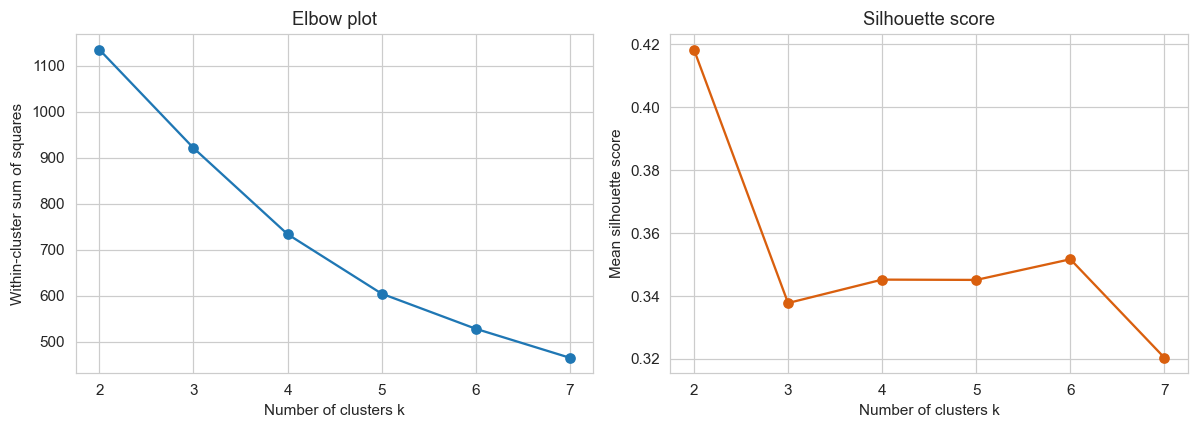

Chosen k: 3 (best silhouette between 3 and 4, with no cluster smaller than 5 days)


,inertia,silhouette,days in smallest cluster
k,,,
2,1134.557,0.418,122
3,921.053,0.338,57
4,733.962,0.345,2
5,604.873,0.345,2
6,528.683,0.352,2
7,465.721,0.320,2


In [19]:
ks = range(2, 8)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_reg)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_reg, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, marker="o")
axes[0].set_title("Elbow plot")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[1].plot(list(ks), sil, marker="o", color="#d95f0e")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Mean silhouette score")
fig.tight_layout()
save_fig("kmeans_elbow_silhouette.png")
plt.show()

smallest = {k: int(np.bincount(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_reg).labels_).min()) for k in ks}
k_table = pd.DataFrame({"inertia": inertia, "silhouette": sil, "days in smallest cluster": smallest},
                       index=pd.Index(list(ks), name="k")).round(3)
eligible = [k for k in (3, 4) if k_table.loc[k, "days in smallest cluster"] >= 5]
best_k = max(eligible, key=lambda k: k_table.loc[k, "silhouette"])
print("Chosen k:", best_k, "(best silhouette between 3 and 4, with no cluster smaller than 5 days)")
k_table

**What we see:** There is no sharp elbow.
Silhouette is best at k = 2 (0.42), but that only splits clean days from the rest.
Between 3 and 4, k = 4 scores a little higher (0.345, against 0.338). But k = 4 only splits off 2 days.
They are 25 Jun and 21 Oct. NO2 was close to zero on both days.
We use k = 3.

### Day types

We sort the clusters by mean PM2.5 and name them.

In [20]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=SEED).fit(X_reg)
reg["cluster"] = km.labels_
order = reg.groupby("cluster")["pm25"].mean().sort_values().index
reg["cluster"] = reg["cluster"].map({old: new for new, old in enumerate(order)})

profile = reg.groupby("cluster").agg(
    days=("pm25", "size"), mean_pm25=("pm25", "mean"), median_pm25=("pm25", "median"), mean_no2=("no2", "mean"),
    mean_ratio=("pm_no2_ratio", "mean"), mean_fires=("fire_count", "mean"), median_fires=("fire_count", "median"))
profile["main months"] = reg.groupby("cluster")["month_name"].agg(
    lambda s: ", ".join(s.value_counts().head(3).index))
profile.round(1)

,days,mean_pm25,median_pm25,mean_no2,mean_ratio,mean_fires,median_fires,main months
cluster,,,,,,,,
0,98,23.4,22.4,18.0,1.9,2.4,1.0,"Jul, Aug, Sep"
1,116,59.0,52.4,29.0,2.3,44.2,39.5,"Mar, Oct, Apr"
2,57,120.6,74.8,33.7,4.2,362.5,241.0,"Nov, May, Apr"


**What we see:** Clean monsoon days (98 days) have mean PM2.5 of 23 and almost no fires.
Moderate hazy days (116 days) have mean PM2.5 of 59 and about 44 fires.
Smoke days (57 days) have mean PM2.5 of 121 and about 363 fires.
The ratio climbs too: 1.9, 2.3 and 4.2.

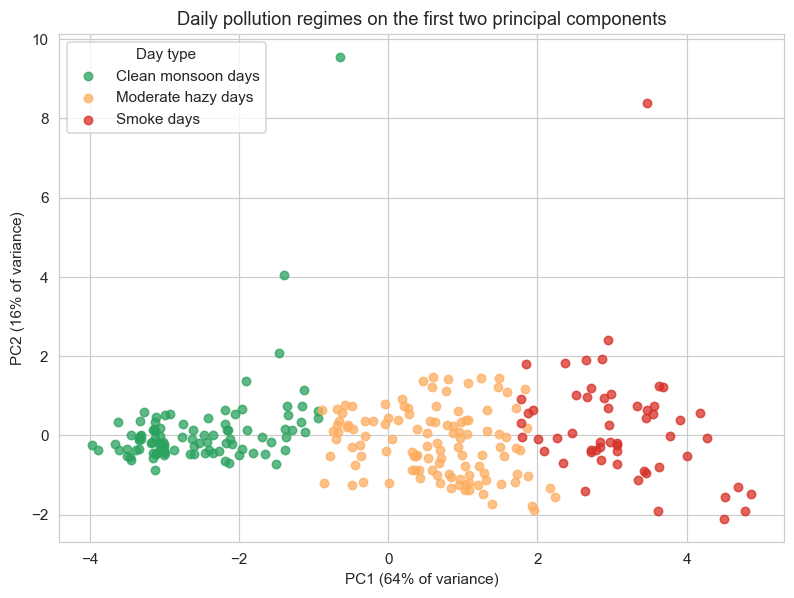

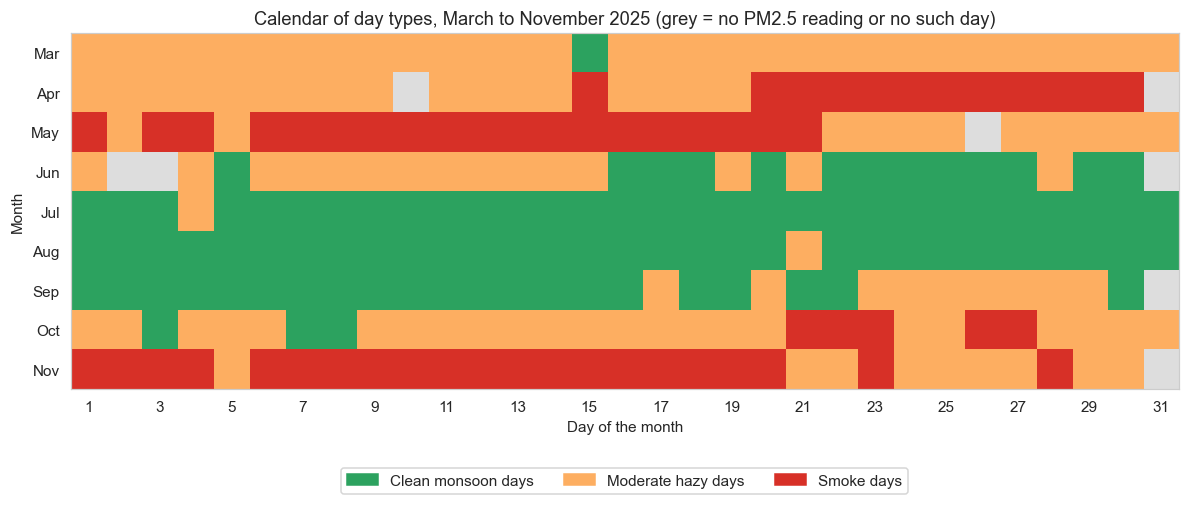

regime,Clean monsoon days,Moderate hazy days,Smoke days
month_name,,,
Mar,1,30,0
Apr,0,17,12
May,0,11,19
Jun,13,15,0
Jul,30,1,0
Aug,30,1,0
Sep,21,9,0
Oct,3,23,5
Nov,0,9,21


In [21]:
REGIME_NAMES = {0: "Clean monsoon days", 1: "Moderate hazy days", 2: "Smoke days"}
assert len(REGIME_NAMES) == best_k
reg["regime"] = reg["cluster"].map(REGIME_NAMES)
colors = dict(zip(REGIME_NAMES.values(), ["#2ca25f", "#fdae61", "#d73027", "#7f0000"][:best_k]))

fig, ax = plt.subplots(figsize=(8.5, 6))
for name in REGIME_NAMES.values():
    part = scores_pc[(reg["regime"] == name).to_numpy()]
    ax.scatter(part[:, 0], part[:, 1], s=30, alpha=0.75, color=colors[name], label=name)
ax.set_xlabel(f"PC1 ({explained['PC1'] * 100:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({explained['PC2'] * 100:.0f}% of variance)")
ax.set_title("Daily pollution regimes on the first two principal components")
ax.legend(title="Day type")
save_fig("regimes_pca_scatter.png")
plt.show()

strip = np.full((9, 31), np.nan)
for d, c in reg["cluster"].items():
    strip[d.month - 3, d.day - 1] = c
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.imshow(np.ma.masked_invalid(strip), cmap=ListedColormap([colors[n] for n in REGIME_NAMES.values()]),
          vmin=-0.5, vmax=best_k - 0.5, aspect="auto")
ax.set_facecolor("#dddddd")
ax.grid(False)
ax.set_yticks(range(9))
ax.set_yticklabels(MONTHS)
ax.set_xticks(range(0, 31, 2))
ax.set_xticklabels(range(1, 32, 2))
ax.set_xlabel("Day of the month")
ax.set_ylabel("Month")
ax.set_title("Calendar of day types, March to November 2025 (grey = no PM2.5 reading or no such day)")
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[n]) for n in REGIME_NAMES.values()]
ax.legend(handles, list(REGIME_NAMES.values()), loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=best_k)
save_fig("regimes_calendar.png")
plt.show()
pd.crosstab(reg["month_name"], reg["regime"]).reindex(MONTHS)[list(REGIME_NAMES.values())]

**What we see:** PC1 does most of the separating. Day type follows the overall pollution and fire level.
Clean days fill July and August.
Smoke days appear in late April and May, then again from late October. In November, 21 of 30 days are smoke days.
The wheat season has smoke days too. Smoke is not only a November story.

## 7. Final feature list

Here we pick the features for the combined model.
We start with 8 pollution and calendar features and 14 fire features.
First we check that no feature looks at the future.

In [22]:
fire_lagged = fires.copy()
for col in ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300"]:
    fire_lagged[f"{col}_lag1"] = fire_lagged[col].shift(1)

POLL = ["no2", "pm25_lag1", "pm25_roll7", "month", "dayofweek", "is_weekend", "doy_sin", "doy_cos"]
FIRE = ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300", "fire_nw", "fire_south", "fire_night",
        "fire_count_lag1", "fire_frp_lag1", "fire_frp_distw_lag1", "fire_near300_lag1",
        "fire_count_prev3", "fire_count_prev7", "is_burning_season"]
model_df = pollution[["pm25"] + POLL].join(fire_lagged[FIRE], how="left")
assert model_df.isna().sum().sum() == 0 and len(model_df) == 264
y = model_df["pm25"]
print("Modelling table:", model_df.shape, "|", model_df.index.min().date(), "to", model_df.index.max().date())

Modelling table: (264, 23) | 2025-03-08 to 2025-11-30


In [23]:
# Leakage check: one row from the middle, next to the raw series.
mid = model_df.index[len(model_df) // 2]
prev_days = topic["pm25"].loc[mid - pd.Timedelta(days=7): mid]
fire_prev = fires["fire_count"].loc[mid - pd.Timedelta(days=3): mid]
print("Test day:", mid.date(), "| PM2.5 on that day (the target):", round(topic.loc[mid, "pm25"], 1))
print("pm25_lag1 in the table:", round(model_df.loc[mid, "pm25_lag1"], 1),
      "| raw PM2.5 the day before:", round(topic["pm25"].loc[mid - pd.Timedelta(days=1)], 1))
print("pm25_roll7 in the table:", round(model_df.loc[mid, "pm25_roll7"], 1),
      "| mean of the 7 raw days before:", round(topic["pm25"].loc[mid - pd.Timedelta(days=7): mid - pd.Timedelta(days=1)].mean(), 1))
print("fire_count_prev3 in the table:", model_df.loc[mid, "fire_count_prev3"],
      "| fires on the 3 days before:", fires["fire_count"].loc[mid - pd.Timedelta(days=3): mid - pd.Timedelta(days=1)].sum())
print("Raw fire counts, 3 days before and the day itself:", fire_prev.to_dict().values())

# the same rules, checked on every row
shifted = fires["fire_count"].shift(1)
assert (fire_lagged["fire_count_prev3"] == shifted.rolling(3, min_periods=1).sum().fillna(0)).all()
assert (fire_lagged["fire_count_prev7"] == shifted.rolling(7, min_periods=1).sum().fillna(0)).all()
assert (model_df["fire_count_lag1"] == fires["fire_count"].shift(1).reindex(model_df.index)).all()
print("Lag and rolling fire features only use earlier days: checked on all rows.")

Test day: 2025-07-22 | PM2.5 on that day (the target): 23.6
pm25_lag1 in the table: 37.5 | raw PM2.5 the day before: 37.5
pm25_roll7 in the table: 22.4 | mean of the 7 raw days before: 22.4
fire_count_prev3 in the table: 5.0 | fires on the 3 days before: 5
Raw fire counts, 3 days before and the day itself: dict_values([2, 3, 0, 0])
Lag and rolling fire features only use earlier days: checked on all rows.


**What we see:** On 22 Jul, `pm25_lag1` in the table is 37.5. That is the raw PM2.5 of 21 Jul.
`pm25_roll7` matches the mean of the 7 days before.
Fire lags and rolling sums also use only earlier days. We checked every row.

We rank all 22 candidates with three methods.
Mutual information is a filter. RFE with linear regression is a wrapper. Random forest importance is embedded.
Rank 1 is best.
We use only the first 220 days. The last fold stays unseen. Earlier folds are slightly optimistic.

In [24]:
SELECT_DAYS = 220          # selection sees only the first 220 days, the last fold stays unseen
cand = POLL + FIRE
sel = model_df.iloc[:SELECT_DAYS]
X_sel, y_sel = sel[cand], np.log1p(sel["pm25"])

mi = pd.Series(mutual_info_regression(X_sel, y_sel, random_state=SEED), index=cand)
rfe = RFE(LinearRegression(), n_features_to_select=1).fit(StandardScaler().fit_transform(X_sel), y_sel)
rf_sel = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(X_sel, y_sel)

ranking = pd.DataFrame({
    "mutual info (filter)": mi, "rank MI": mi.rank(ascending=False),
    "rank RFE (wrapper)": pd.Series(rfe.ranking_, index=cand),
    "RF importance (embedded)": pd.Series(rf_sel.feature_importances_, index=cand)})
ranking["rank RF"] = ranking["RF importance (embedded)"].rank(ascending=False)
ranking["mean rank"] = ranking[["rank MI", "rank RFE (wrapper)", "rank RF"]].mean(axis=1)
ranking = ranking.sort_values("mean rank")
ranking.round(3)

,mutual info (filter),rank MI,rank RFE (wrapper),RF importance (embedded),rank RF,mean rank
pm25_lag1,0.624,1.0,6,0.379,1.0,2.667
fire_count,0.406,9.0,1,0.066,4.0,4.667
fire_count_lag1,0.406,8.0,4,0.072,3.0,5.000
pm25_roll7,0.460,4.0,7,0.063,5.0,5.333
fire_count_prev3,0.435,6.0,8,0.072,2.0,5.333
fire_near300,0.403,10.0,3,0.053,6.0,6.333
fire_count_prev7,0.449,5.0,9,0.033,10.0,8.000
fire_near300_lag1,0.386,12.0,5,0.047,8.0,8.333
doy_sin,0.530,3.0,11,0.018,13.0,9.000
fire_frp_distw_lag1,0.394,11.0,10,0.046,9.0,10.000


**What we see:** `pm25_lag1` is the top feature (ranks 1, 6 and 1).
Fire count and its lag come next.
Many fire columns rank well, but they say the same thing.

Now we drop one feature from each pair with |r| above 0.85.
We keep the one with the better mean rank.

In [25]:
corr = sel[cand].corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(cand) for b in cand[i + 1:] if abs(corr.loc[a, b]) > 0.85]
pairs.sort(key=lambda t: -abs(t[2]))

dropped, pair_rows = {}, []
for a, b, r in pairs:
    if a in dropped or b in dropped:
        pair_rows.append({"feature 1": a, "feature 2": b, "r": round(r, 2), "dropped": "(one is already gone)"})
        continue
    loser = a if ranking.loc[a, "mean rank"] > ranking.loc[b, "mean rank"] else b
    dropped[loser] = a if loser == b else b
    pair_rows.append({"feature 1": a, "feature 2": b, "r": round(r, 2), "dropped": loser})

print(f"{len(pairs)} pairs have |r| above 0.85 on the first {SELECT_DAYS} days. {len(dropped)} features dropped.")
pd.DataFrame(pair_rows)

21 pairs have |r| above 0.85 on the first 220 days. 10 features dropped.


,feature 1,feature 2,r,dropped
0,fire_count,fire_near300,0.99,fire_near300
1,fire_count_lag1,fire_near300_lag1,0.99,fire_near300_lag1
2,month,doy_sin,-0.97,month
3,fire_count,fire_frp,0.96,fire_frp
4,fire_count_lag1,fire_frp_lag1,0.96,fire_frp_lag1
5,fire_count,fire_nw,0.96,fire_nw
6,fire_frp_lag1,fire_frp_distw_lag1,0.95,(one is already gone)
7,fire_frp,fire_frp_distw,0.95,(one is already gone)
8,fire_count_prev3,fire_count_prev7,0.95,fire_count_prev7
9,fire_frp,fire_near300,0.95,(one is already gone)


**What we see:** 21 pairs are above 0.85. Nearly all are fire columns. Fire count and fires within 300 km have r = 0.99.
We drop 10 features.
`month` goes too. It is -0.97 correlated with `doy_sin`.

Last, we keep features with a mean rank of 12 or better.

In [26]:
survivors = ranking.drop(index=list(dropped))
MAX_MEAN_RANK = 12          # keep features with an average rank in the better half of the 22 candidates
FINAL = survivors.loc[survivors["mean rank"] <= MAX_MEAN_RANK].sort_values("mean rank").index.tolist()


def reason(feat):
    row = ranking.loc[feat]
    votes = [name for name, col in [("mutual information", "rank MI"), ("RFE", "rank RFE (wrapper)"),
                                     ("random forest", "rank RF")] if row[col] <= 8]
    family = ("fire" if feat in FIRE else "calendar" if feat in ("month", "dayofweek", "is_weekend", "doy_sin", "doy_cos")
              else "traffic signal" if feat == "no2" else "pollution history")
    why = f"top 8 in {', '.join(votes)}" if votes else "good average rank"
    return f"{family} feature, {why}"


final_table = pd.DataFrame({"mean rank": ranking.loc[FINAL, "mean rank"].round(1),
                            "reason": [reason(f) for f in FINAL]})
left_out = survivors.drop(index=FINAL)
print("Final list:", FINAL)
print("Left out because of weak rank:", left_out.index.tolist())
print("Dropped for collinearity:", list(dropped))
final_table

Final list: ['pm25_lag1', 'fire_count', 'fire_count_lag1', 'pm25_roll7', 'doy_sin', 'no2']
Left out because of weak rank: ['doy_cos', 'fire_south', 'fire_night', 'dayofweek', 'is_burning_season', 'is_weekend']
Dropped for collinearity: ['fire_near300', 'fire_near300_lag1', 'month', 'fire_frp', 'fire_frp_lag1', 'fire_nw', 'fire_count_prev7', 'fire_frp_distw_lag1', 'fire_frp_distw', 'fire_count_prev3']


,mean rank,reason
pm25_lag1,2.7,"pollution history feature, top 8 in mutual inf..."
fire_count,4.7,"fire feature, top 8 in RFE, random forest"
fire_count_lag1,5.0,"fire feature, top 8 in mutual information, RFE..."
pm25_roll7,5.3,"pollution history feature, top 8 in mutual inf..."
doy_sin,9.0,"calendar feature, top 8 in mutual information"
no2,11.7,"traffic signal feature, top 8 in random forest"


**What we see:** The list has 2 pollution history features, NO2, one seasonal term and 2 fire features.
Left out: `doy_cos`, `fire_south`, `fire_night`, `dayofweek`, `is_burning_season` and `is_weekend`.
They rank poorly or add little.

## 8. Models

We train three models on each feature set: Linear Regression, a tuned Decision Tree and a Random Forest.
Every model predicts log(1 + PM2.5). We convert back to µg/m³ before scoring.
The split is walk-forward with 5 folds.

- **Model A** uses pollution features only.
- **Model B** uses fire features only.
- **Model C** uses the final list.

Linear Regression gets log(1 + x) on skewed columns first.
We add two baselines: the training mean, and persistence (today equals yesterday).

In [27]:
LOG_COLS = {c for c in POLL + FIRE if c.startswith("fire_")} | {"pm25_lag1", "pm25_roll7", "no2"}
LOG_COLS.discard("is_burning_season")


def make_lr():
    """Linear model: skewed count columns go through log(1 + x) first, then everything is scaled."""
    logged = Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())])
    prep = ColumnTransformer([("log", logged, lambda df: [c for c in df.columns if c in LOG_COLS])],
                             remainder=StandardScaler())
    return Pipeline([("prep", prep), ("lr", LinearRegression())])


def make_tree():
    return GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                        {"max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [1, 5, 10]},
                        cv=TimeSeriesSplit(n_splits=3), scoring="neg_mean_absolute_error")


def make_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)


FEATURE_SETS = {"Pollution only (A)": POLL, "Fires only (B)": FIRE, "Combined (C)": FINAL}
BUILT_BY = {"Baseline": "Together", "Pollution only (A)": "Yashvi", "Fires only (B)": "Khushi", "Combined (C)": "Together"}

rows, folds_by_model, oof_by_model = [], {}, {}


def run_model(set_name, algo, make, cols):
    folds, oof = walk_forward(make, model_df[cols], y)
    done = oof.notna()
    pooled = score(y[done], oof[done])
    rows.append({"set": set_name, "algorithm": algo, "built by": BUILT_BY[set_name], "features": len(cols),
                 "MAE": folds["MAE"].mean(), "MAE std": folds["MAE"].std(ddof=0),
                 "RMSE": pooled["RMSE"], "R2": pooled["R2"]})
    folds_by_model[(set_name, algo)] = folds
    oof_by_model[(set_name, algo)] = oof


run_model("Baseline", "Training mean", TrainMean, ["pm25_lag1"])
run_model("Baseline", "Persistence", Persistence, ["pm25_lag1"])
for set_name, cols in FEATURE_SETS.items():
    for algo, make in [("Linear Regression", make_lr), ("Decision Tree (tuned)", make_tree), ("Random Forest", make_rf)]:
        run_model(set_name, algo, make, cols)

results = pd.DataFrame(rows)
results.round(2)

,set,algorithm,built by,features,MAE,MAE std,RMSE,R2
0,Baseline,Training mean,Together,1,39.66,36.87,64.08,-0.14
1,Baseline,Persistence,Together,1,16.22,13.61,35.71,0.64
2,Pollution only (A),Linear Regression,Yashvi,8,20.95,9.09,35.32,0.65
3,Pollution only (A),Decision Tree (tuned),Yashvi,8,32.05,32.82,56.59,0.11
4,Pollution only (A),Random Forest,Yashvi,8,31.44,35.75,58.06,0.06
5,Fires only (B),Linear Regression,Khushi,14,172.24,283.48,527.23,-76.48
6,Fires only (B),Decision Tree (tuned),Khushi,14,29.36,32.94,55.14,0.15
7,Fires only (B),Random Forest,Khushi,14,26.71,34.66,54.87,0.16
8,Combined (C),Linear Regression,Together,6,24.19,19.06,42.36,0.50
9,Combined (C),Decision Tree (tuned),Together,6,27.58,32.80,54.66,0.17


**What we see:** Persistence has MAE 16.2 µg/m³. No trained model beats it on average.
The best of each set: A linear, 21.0. C linear, 24.2. B forest, 26.7.
B linear is unstable (MAE 172). Its fire columns are near copies of each other.

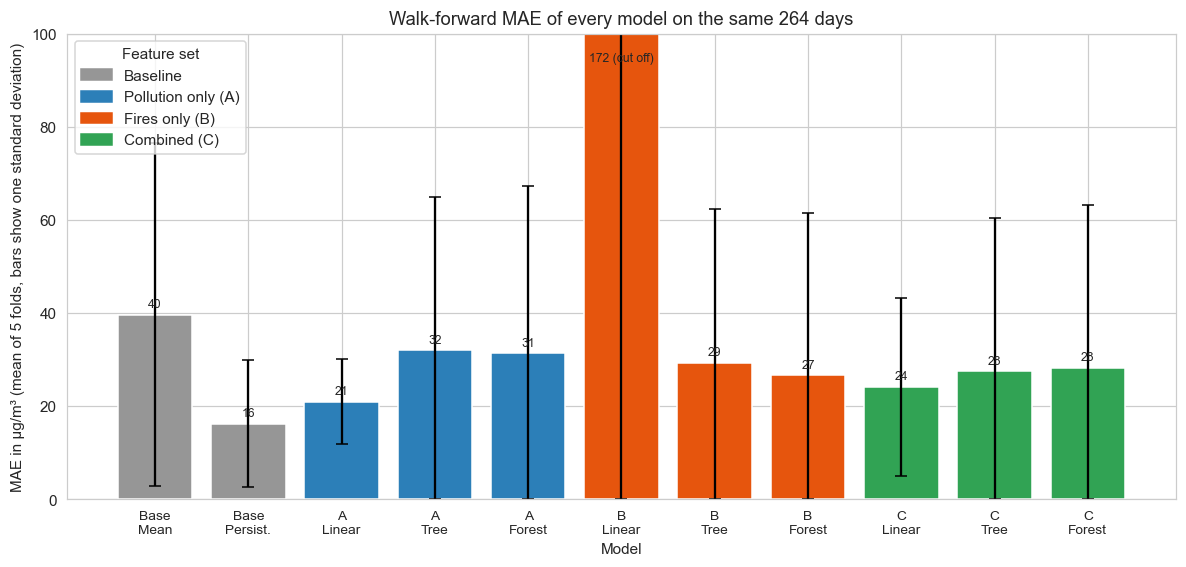

In [28]:
short = {"Linear Regression": "Linear", "Decision Tree (tuned)": "Tree", "Random Forest": "Forest",
         "Training mean": "Mean", "Persistence": "Persist."}
tag = {"Baseline": "Base", "Pollution only (A)": "A", "Fires only (B)": "B", "Combined (C)": "C"}
results["label"] = results["set"].map(tag) + "\n" + results["algorithm"].map(short)
palette = {"Baseline": "#969696", "Pollution only (A)": "#2c7fb8", "Fires only (B)": "#e6550d", "Combined (C)": "#31a354"}
YMAX = 100
fig, ax = plt.subplots(figsize=(13, 5.5))
lower = np.minimum(results["MAE std"], results["MAE"])
ax.bar(range(len(results)), results["MAE"], yerr=[lower, results["MAE std"]], capsize=4,
       color=[palette[s] for s in results["set"]], edgecolor="white")
ax.set_ylim(0, YMAX)
for i, v in enumerate(results["MAE"]):
    ax.text(i, min(v, YMAX) + 1.5 if v < YMAX else YMAX - 6, f"{v:.0f}" if v < YMAX else f"{v:.0f} (cut off)",
            ha="center", fontsize=8)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(results["label"], fontsize=9)
ax.set_ylabel("MAE in µg/m³ (mean of 5 folds, bars show one standard deviation)")
ax.set_xlabel("Model")
ax.set_title("Walk-forward MAE of every model on the same 264 days")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), title="Feature set", loc="upper left")
save_fig("model_comparison_mae.png")
plt.show()



**What we see:** The B linear bar is cut off at 100.
The error bars are wide. The spread between folds is bigger than most gaps between models.

In [29]:
best = results[results["set"] != "Baseline"].loc[lambda d: d.groupby("set")["MAE"].idxmin()].set_index("set")
base = results.set_index(["set", "algorithm"])["MAE"]
summary = pd.DataFrame({"best algorithm": best["algorithm"], "MAE": best["MAE"].round(2), "RMSE": best["RMSE"].round(2),
                        "R2": best["R2"].round(2)})
print("Persistence MAE:", round(base[("Baseline", "Persistence")], 2), "| training mean MAE:", round(base[("Baseline", "Training mean")], 2))
print("Model C minus Model A (negative means C is better):", round(best.loc["Combined (C)", "MAE"] - best.loc["Pollution only (A)", "MAE"], 2))
print("Model C minus Model B (negative means C is better):", round(best.loc["Combined (C)", "MAE"] - best.loc["Fires only (B)", "MAE"], 2))
summary

Persistence MAE: 16.22 | training mean MAE: 39.66
Model C minus Model A (negative means C is better): 3.24
Model C minus Model B (negative means C is better): -2.52


,best algorithm,MAE,RMSE,R2
set,,,,
Combined (C),Linear Regression,24.19,42.36,0.50
Fires only (B),Random Forest,26.71,54.87,0.16
Pollution only (A),Linear Regression,20.95,35.32,0.65


**Does Model C beat A and B?** C beats B by 2.5 µg/m³ of MAE. C does not beat A. A is 3.2 µg/m³ better.
These gaps are small against the fold spread.
Once pollution history is in the model, fire data does not lower the average error.

In [30]:
best_c = best.loc["Combined (C)", "algorithm"]
fold_table = pd.DataFrame({
    "test period starts": folds_by_model[("Combined (C)", best_c)]["first_test_day"].astype(str),
    "Persistence": folds_by_model[("Baseline", "Persistence")]["MAE"],
    "Model A": folds_by_model[("Pollution only (A)", best.loc["Pollution only (A)", "algorithm"])]["MAE"],
    "Model B": folds_by_model[("Fires only (B)", best.loc["Fires only (B)", "algorithm"])]["MAE"],
    "Model C": folds_by_model[("Combined (C)", best_c)]["MAE"]}).round(1)
fold_table.index = fold_table.index + 1
fold_table.index.name = "fold"

saved_a = pd.read_csv(DATA / "model_a_fold_scores.csv")
saved_rf = saved_a.loc[saved_a["Model"] == "Random Forest", "MAE"].mean()
print(f"Cross-check: Model A random forest in the saved file has MAE {saved_rf:.1f}; here it has "
      f"{results.set_index(['set', 'algorithm']).loc[('Pollution only (A)', 'Random Forest'), 'MAE']:.1f}.")
fold_table

Cross-check: Model A random forest in the saved file has MAE 34.1; here it has 31.4.


,test period starts,Persistence,Model A,Model B,Model C
fold,,,,,
1,2025-04-22,20.6,25.5,15.5,27.7
2,2025-06-08,6.7,14.1,7.4,17.0
3,2025-07-22,5.6,9.5,6.1,4.9
4,2025-09-04,7.1,20.1,8.8,12.1
5,2025-10-18,41.1,35.6,95.7,59.3


**What we see:** Fold 5 runs from 18 Oct to 30 Nov. Every model struggles there.
Only Model A (35.6) beats persistence (41.1). Model C scores 59.3. Model B scores 95.7.
In folds 2 to 4, errors are much smaller for every model.
Our Model A forest scores 31.4 here. The saved Model A file shows 34.1. We use a leaf size of 3.

### Reading the linear model

The table shows the Model C linear fit on all days.
One unit is one standard deviation of the feature, after the log step.

In [31]:
lr_c = make_lr().fit(model_df[FINAL], np.log1p(y))
coef_names = [c for c in FINAL if c in LOG_COLS] + [c for c in FINAL if c not in LOG_COLS]
coefs = pd.Series(lr_c.named_steps["lr"].coef_, index=coef_names)
coef_table = pd.DataFrame({"coefficient (log PM2.5 per 1 SD)": coefs,
                           "change in PM2.5 per 1 SD (%)": (np.exp(coefs) - 1) * 100}).round(2)
coef_table.sort_values("coefficient (log PM2.5 per 1 SD)", ascending=False)

,coefficient (log PM2.5 per 1 SD),change in PM2.5 per 1 SD (%)
pm25_lag1,0.39,47.79
fire_count,0.16,16.99
pm25_roll7,0.16,17.69
no2,0.04,3.87
fire_count_lag1,0.00,0.34
doy_sin,-0.07,-7.01


**What we see:** Yesterday's PM2.5 matters most. One SD more raises today's PM2.5 by about 48%.
One SD more fire count raises it by about 17%.
The lagged fire count adds almost nothing.

### What each feature group adds

We add features in steps. We use a random forest.

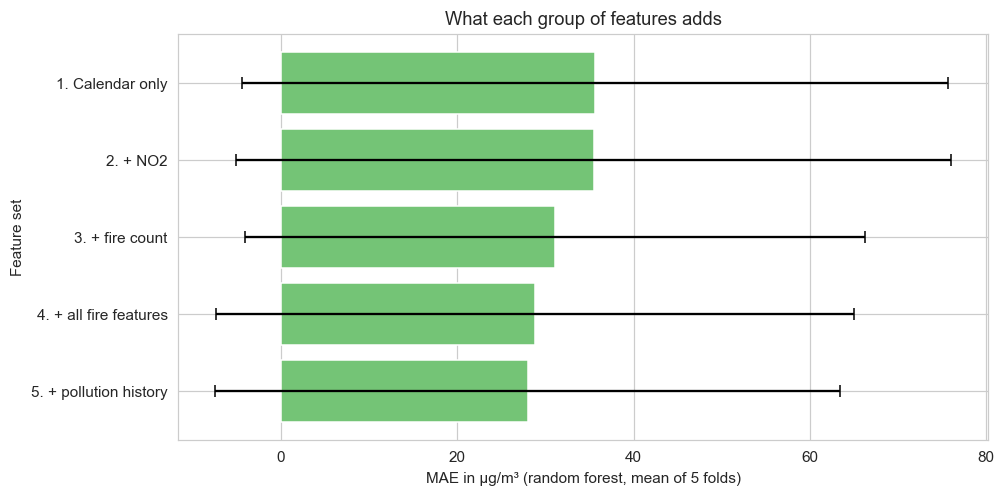

,features,MAE,MAE std,fold 5 MAE
feature set,,,,
1. Calendar only,5,35.64,40.01,114.83
2. + NO2,6,35.47,40.59,115.94
3. + fire count,7,31.08,35.15,100.68
4. + all fire features,20,28.84,36.15,100.86
5. + pollution history,22,27.99,35.43,98.59


In [32]:
CAL = ["month", "dayofweek", "is_weekend", "doy_sin", "doy_cos"]
steps = {
    "1. Calendar only": CAL,
    "2. + NO2": CAL + ["no2"],
    "3. + fire count": CAL + ["no2", "fire_count"],
    "4. + all fire features": CAL + ["no2"] + FIRE,
    "5. + pollution history": CAL + ["no2"] + FIRE + ["pm25_lag1", "pm25_roll7"],
}
sens = []
for name, cols in steps.items():
    folds, _ = walk_forward(make_rf, model_df[cols], y)
    sens.append({"feature set": name, "features": len(cols), "MAE": folds["MAE"].mean(), "MAE std": folds["MAE"].std(ddof=0),
                 "fold 5 MAE": folds["MAE"].iloc[-1]})
sens = pd.DataFrame(sens).set_index("feature set")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.barh(sens.index[::-1], sens["MAE"][::-1], xerr=sens["MAE std"][::-1], capsize=4, color="#74c476")
ax.set_xlabel("MAE in µg/m³ (random forest, mean of 5 folds)")
ax.set_ylabel("Feature set")
ax.set_title("What each group of features adds")
save_fig("feature_set_sensitivity.png")
plt.show()
sens.round(2)

**What we see:** Calendar only gives MAE 35.7. NO2 adds nothing.
Fire count brings it to 31.1. All fire features bring it to 28.8. Pollution history brings it to 28.0.
Fires give the biggest gain after the calendar.
Fold 5 stays near 100 in every row.

### Does the cleaning choice matter?

We change how the training target is cleaned. We always score on the real PM2.5.
P1 is the baseline. P2 caps high values at the IQR fence. P3 winsorises 5% at both ends. P4 drops the log.

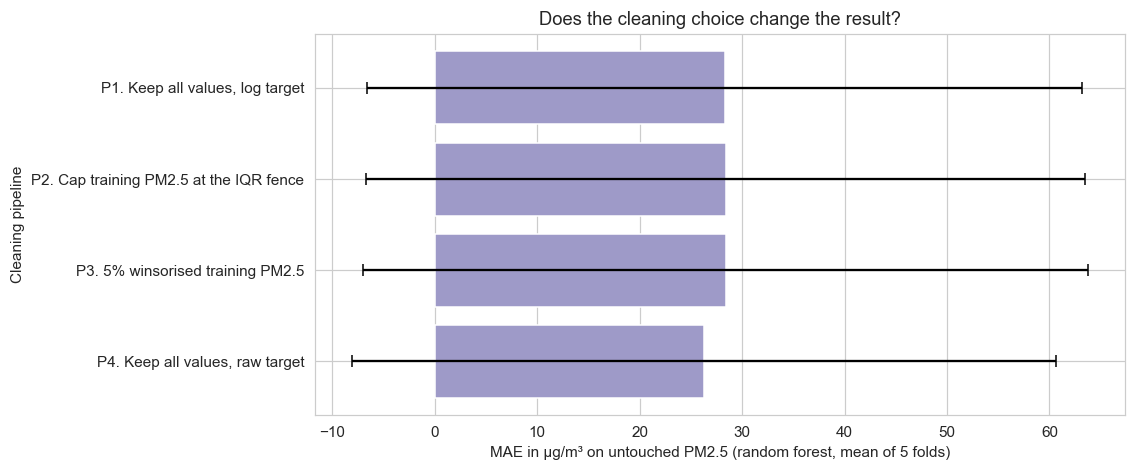

,MAE,MAE std
"P1. Keep all values, log target",28.30,34.88
P2. Cap training PM2.5 at the IQR fence,28.40,35.09
P3. 5% winsorised training PM2.5,28.39,35.36
"P4. Keep all values, raw target",26.28,34.40


In [33]:
def fit_variant(prep, log_target=True):
    maes = []
    for tr, te in TimeSeriesSplit(n_splits=5).split(model_df):
        y_train = prep(y.iloc[tr])
        m = make_rf()
        m.fit(model_df[FINAL].iloc[tr], np.log1p(y_train) if log_target else y_train)
        pred = m.predict(model_df[FINAL].iloc[te])
        pred = np.expm1(pred) if log_target else pred
        maes.append(mean_absolute_error(y.iloc[te], np.clip(pred, 0, None)))
    return maes


def cap_at_fence(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s.clip(upper=q3 + 1.5 * (q3 - q1))


def winsorise(s):
    return s.clip(lower=s.quantile(0.05), upper=s.quantile(0.95))


pipelines = {
    "P1. Keep all values, log target": (lambda s: s, True),
    "P2. Cap training PM2.5 at the IQR fence": (cap_at_fence, True),
    "P3. 5% winsorised training PM2.5": (winsorise, True),
    "P4. Keep all values, raw target": (lambda s: s, False),
}
clean = {name: fit_variant(*args) for name, args in pipelines.items()}
clean_table = pd.DataFrame({"MAE": {k: np.mean(v) for k, v in clean.items()},
                            "MAE std": {k: np.std(v) for k, v in clean.items()}})

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.barh(clean_table.index[::-1], clean_table["MAE"][::-1], xerr=clean_table["MAE std"][::-1], capsize=4, color="#9e9ac8")
ax.set_xlabel("MAE in µg/m³ on untouched PM2.5 (random forest, mean of 5 folds)")
ax.set_ylabel("Cleaning pipeline")
ax.set_title("Does the cleaning choice change the result?")
save_fig("cleaning_sensitivity.png")
plt.show()
clean_table.round(2)

**What we see:** P2 and P3 score the same as P1 (28.3 to 28.4). Capping the Diwali spike does not help.
P4 is 2 µg/m³ better (26.3). That is small against the fold spread of about 35.
We keep the log target. The other models here use it too.

## 9. AQI category prediction

We predict the AQI category of each day.
We use Logistic Regression and a Decision Tree on the final features.
The walk-forward split is the same.
The baseline is yesterday's category.

Scored on 220 days (the first fold is only used for training).


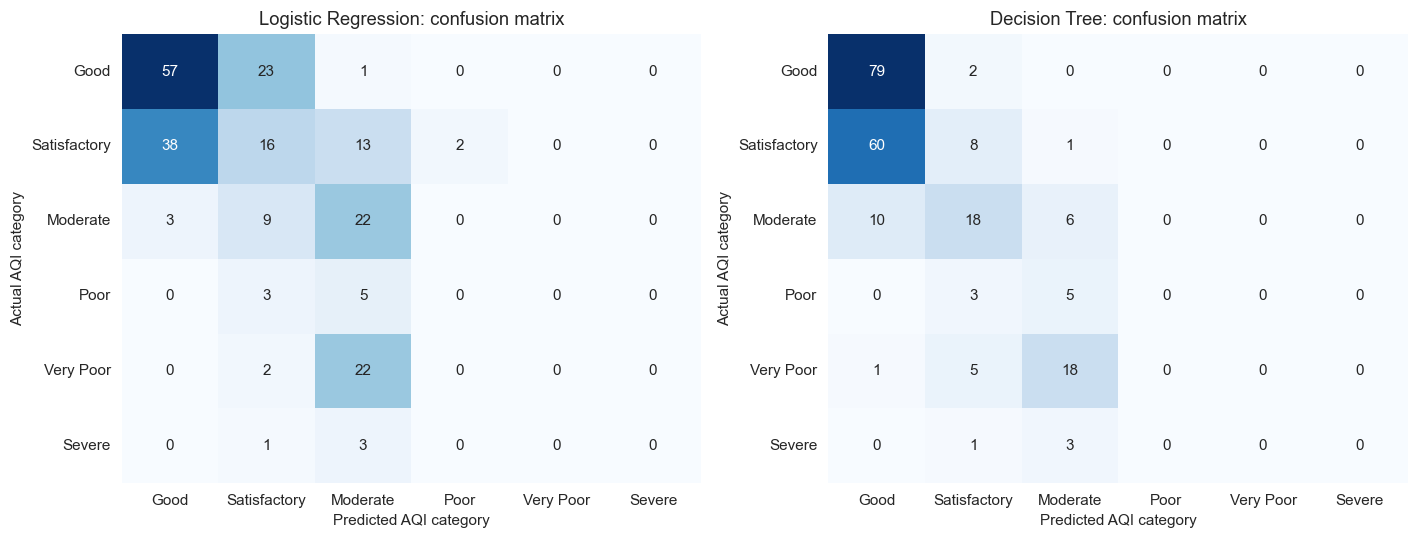

,accuracy,within one category
Logistic Regression,0.432,0.832
Decision Tree,0.423,0.814
Persistence (yesterday's category),0.718,0.968


In [34]:
y_class = pd.cut(y, AQI_BINS, labels=AQI_LABELS)
class_codes = y_class.cat.codes
Xc = model_df[FINAL]
class_models = {
    "Logistic Regression": lambda: Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
    "Decision Tree": lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=SEED),
}
pred_class = {}
for name, make in class_models.items():
    out = pd.Series(-1, index=y.index)
    for tr, te in TimeSeriesSplit(n_splits=5).split(Xc):
        m = make().fit(Xc.iloc[tr], class_codes.iloc[tr])
        out.iloc[te] = m.predict(Xc.iloc[te])
    pred_class[name] = out
pred_class["Persistence (yesterday's category)"] = pd.cut(model_df["pm25_lag1"], AQI_BINS, labels=AQI_LABELS).cat.codes

tested = pred_class["Decision Tree"] >= 0
truth = class_codes[tested]
present = sorted(set(truth) | set(pred_class["Logistic Regression"][tested]) | set(pred_class["Decision Tree"][tested]))
names_present = [AQI_LABELS[i] for i in present]

overview = pd.DataFrame({name: {"accuracy": (p[tested] == truth).mean(),
                                "within one category": ((p[tested] - truth).abs() <= 1).mean()}
                         for name, p in pred_class.items()}).T.round(3)
print(f"Scored on {tested.sum()} days (the first fold is only used for training).")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree"]):
    cmx = confusion_matrix(truth, pred_class[name][tested], labels=present)
    sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", xticklabels=names_present, yticklabels=names_present, ax=ax, cbar=False)
    ax.set_title(f"{name}: confusion matrix")
    ax.set_xlabel("Predicted AQI category")
    ax.set_ylabel("Actual AQI category")
fig.tight_layout()
save_fig("aqi_confusion_matrices.png")
plt.show()
overview

**What we see:** Logistic Regression is right on 43% of days. The tree is right on 42%.
Yesterday's category is right on 72%.
Both models are within one category on 81% to 83% of days.

In [35]:
for name in ["Logistic Regression", "Decision Tree"]:
    print(f"--- {name}")
    print(classification_report(truth, pred_class[name][tested], labels=present, target_names=names_present, zero_division=0, digits=2))

--- Logistic Regression
              precision    recall  f1-score   support

        Good       0.58      0.70      0.64        81
Satisfactory       0.30      0.23      0.26        69
    Moderate       0.33      0.65      0.44        34
        Poor       0.00      0.00      0.00         8
   Very Poor       0.00      0.00      0.00        24
      Severe       0.00      0.00      0.00         4

    accuracy                           0.43       220
   macro avg       0.20      0.26      0.22       220
weighted avg       0.36      0.43      0.38       220

--- Decision Tree
              precision    recall  f1-score   support

        Good       0.53      0.98      0.68        81
Satisfactory       0.22      0.12      0.15        69
    Moderate       0.18      0.18      0.18        34
        Poor       0.00      0.00      0.00         8
   Very Poor       0.00      0.00      0.00        24
      Severe       0.00      0.00      0.00         4

    accuracy                       

**What we see:** Both models find Good days well (recall 0.70 and 0.98).
They never find Poor, Very Poor or Severe days. Their scores are 0.
These classes are rare (8, 24 and 4 days). Very Poor and Severe days are almost all in the last fold.
The models have not seen days that polluted in training.

### One tree rule in words

This tree has depth 3. It is fitted on all days.

In [36]:
rule_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=SEED).fit(Xc, class_codes)
print("Class codes:", dict(enumerate(AQI_LABELS)))
print(export_text(rule_tree, feature_names=list(Xc.columns)))

Class codes: {0: 'Good', 1: 'Satisfactory', 2: 'Moderate', 3: 'Poor', 4: 'Very Poor', 5: 'Severe'}
|--- pm25_roll7 <= 30.51
|   |--- doy_sin <= -0.96
|   |   |--- class: 1
|   |--- doy_sin >  -0.96
|   |   |--- doy_sin <= -0.40
|   |   |   |--- class: 0
|   |   |--- doy_sin >  -0.40
|   |   |   |--- class: 0
|--- pm25_roll7 >  30.51
|   |--- pm25_lag1 <= 102.00
|   |   |--- pm25_lag1 <= 44.86
|   |   |   |--- class: 1
|   |   |--- pm25_lag1 >  44.86
|   |   |   |--- class: 2
|   |--- pm25_lag1 >  102.00
|   |   |--- doy_sin <= -0.73
|   |   |   |--- class: 4
|   |   |--- doy_sin >  -0.73
|   |   |   |--- class: 4



**Reading one rule:** Take a day when the average of the last 7 days is above 30.5 µg/m³.
If yesterday's PM2.5 was also above 102, the tree says the day is Very Poor.
In short, a polluted week followed by a very polluted day stays very polluted.

## 10. Where the model fails

We use the best Model C, which is the linear fit.
A residual is actual minus predicted PM2.5.

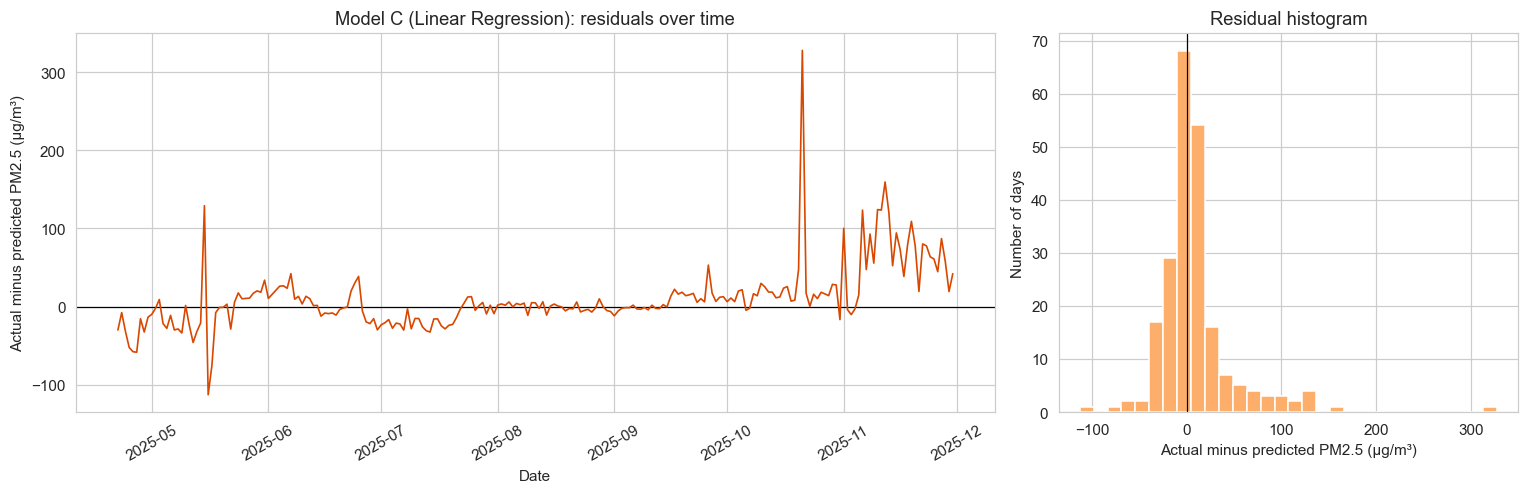

,actual,predicted,error,fires that day
date,,,,
2025-10-21,399.9,72.3,327.7,134
2025-11-12,298.9,139.5,159.4,206
2025-05-15,209.8,80.9,128.9,512
2025-11-10,237.5,113.4,124.0,211
2025-11-11,257.3,133.9,123.4,241
2025-11-06,193.7,70.4,123.3,267
2025-11-13,271.2,150.5,120.7,173
2025-05-16,73.5,186.3,-112.9,1223
2025-11-19,216.5,107.4,109.0,72


In [37]:
champion = ("Combined (C)", best_c)
oof_c = oof_by_model[champion].dropna()
resid = y.loc[oof_c.index] - oof_c

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].axhline(0, color="black", lw=0.8)
axes[0].plot(resid.index, resid, color="#d94801", lw=1.1)
axes[0].set_title(f"Model C ({best_c}): residuals over time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Actual minus predicted PM2.5 (µg/m³)")
axes[0].tick_params(axis="x", rotation=30)
axes[1].hist(resid, bins=30, color="#fdae6b", edgecolor="white")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Residual histogram")
axes[1].set_xlabel("Actual minus predicted PM2.5 (µg/m³)")
axes[1].set_ylabel("Number of days")
fig.tight_layout()
save_fig("model_c_residuals.png")
plt.show()

worst = pd.DataFrame({"actual": y.loc[oof_c.index], "predicted": oof_c, "error": resid, "fires that day": model_df.loc[oof_c.index, "fire_count"]})
worst = worst.reindex(resid.abs().sort_values(ascending=False).index).head(10).round(1)
worst

**What we see:** Most errors are small. A long tail of days is predicted too low.
The average error is 24 µg/m³.
The biggest miss is 21 Oct.

**Why these days fail:**
- 21 Oct: PM2.5 was 399.9 and the model said 72. This is firecracker smoke after Diwali. No feature carries it.
- 6 to 13 Nov: smoke built up past what the fire count shows. The model predicts too low.
- 15 and 16 May: the fire counts were huge (512, then 1,223). PM2.5 was 210 on 15 May and 73.5 on 16 May. The model said 81 and 186. In the wheat season, a big fire count does not mean high PM2.5.

### Why trees cannot go above their training range

A tree predicts the average of the training days in a leaf.
So it cannot predict above the highest training value.
We show this with the random forest version of Model C.

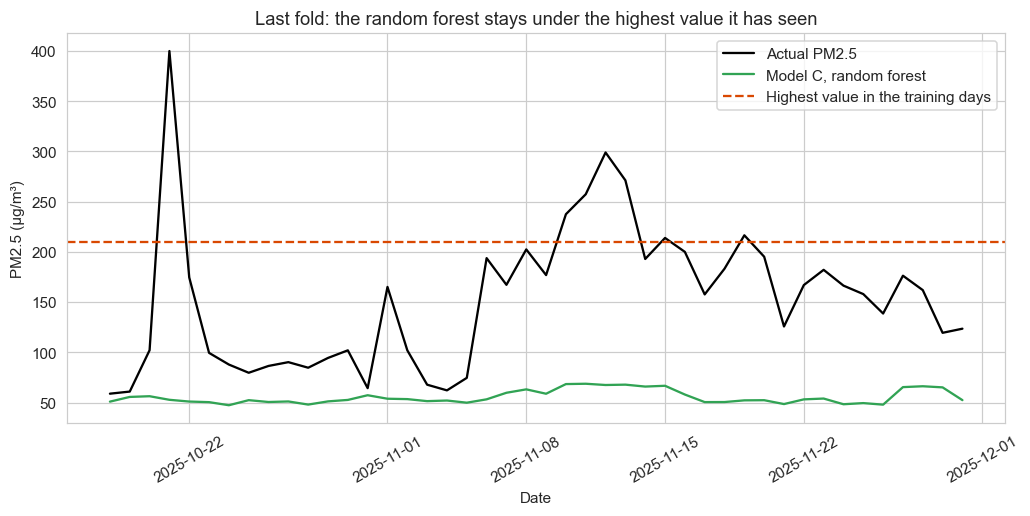

,highest PM2.5 seen in training,highest PM2.5 in the test days,highest prediction
fold,,,
1,96.0,210.0,71.0
2,210.0,69.0,47.0
3,210.0,38.0,27.0
4,210.0,78.0,35.0
5,210.0,400.0,69.0


In [38]:
rf_oof = oof_by_model[("Combined (C)", "Random Forest")]
rows_ext = []
for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5).split(model_df), start=1):
    rows_ext.append({"fold": k, "highest PM2.5 seen in training": y.iloc[tr].max(),
                     "highest PM2.5 in the test days": y.iloc[te].max(),
                     "highest prediction": rf_oof.iloc[te].max()})
ext = pd.DataFrame(rows_ext).set_index("fold").round(0)

last_te = np.arange(len(y))[-44:]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(y.index[last_te], y.iloc[last_te], color="black", label="Actual PM2.5")
ax.plot(y.index[last_te], rf_oof.iloc[last_te], color="#31a354", label="Model C, random forest")
ax.axhline(ext.loc[5, "highest PM2.5 seen in training"], color="#d94801", ls="--", label="Highest value in the training days")
ax.set_title("Last fold: the random forest stays under the highest value it has seen")
ax.set_xlabel("Date")
ax.set_ylabel(PM_LABEL)
ax.tick_params(axis="x", rotation=30)
ax.legend()
save_fig("model_c_extrapolation.png")
plt.show()
ext

**What we see:** In fold 5, the training days peak at 210. The test days reach 400.
The random forest never goes above 69.
The linear model can go higher. That is one reason it does best in November.

### What if there were no fires in November?

We set every fire column to 0 for November. Then the model predicts again.
The gap is the fire contribution.
This is a model estimate. It is not proof of cause.
We repeat the check with other models.

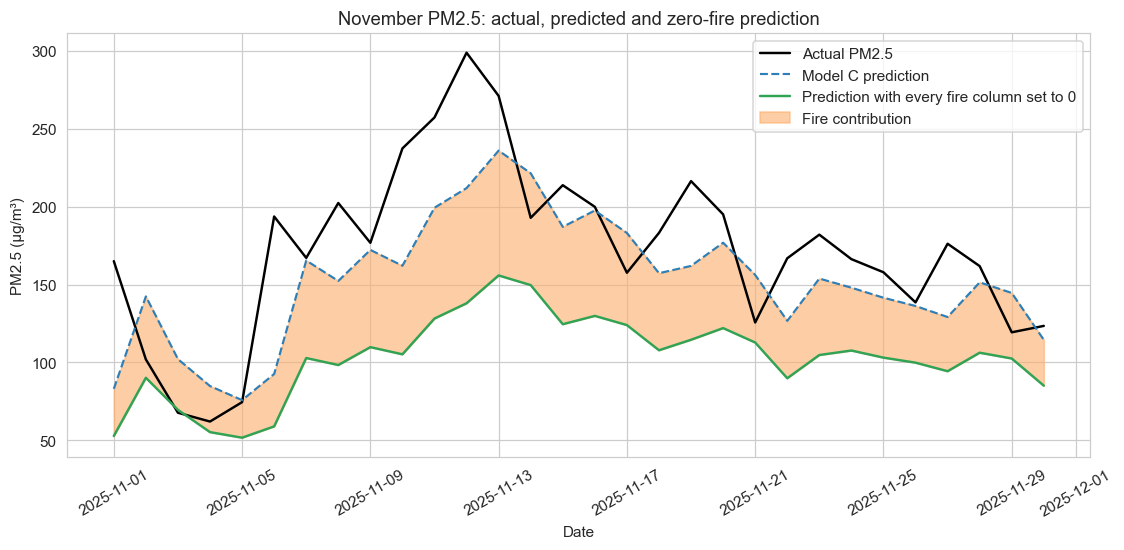

Fire columns set to 0: ['fire_count', 'fire_count_lag1']
November actual mean: 171.8 | predicted mean: 152.3 | zero-fire mean: 103.2


,average gap (µg/m³),largest daily gap (µg/m³)
"Linear Regression, trained on all days",49.1,80.2
"Linear Regression, trained before 17 Oct",36.1,54.7
"Random Forest, trained on all days",96.2,166.5
"Random Forest, trained before 17 Oct",20.0,26.1


In [39]:
nov_days = model_df.index.month == 11
makers = {"Linear Regression": make_lr, "Decision Tree (tuned)": make_tree, "Random Forest": make_rf}
fire_in_model = [c for c in FINAL if c.startswith("fire_")]
nov = model_df.loc[nov_days, FINAL]
nov0 = nov.copy()
nov0[fire_in_model] = 0


def fire_gap(maker, train_mask):
    m = maker().fit(model_df.loc[train_mask, FINAL], np.log1p(y[train_mask]))
    return np.expm1(m.predict(nov)), np.expm1(m.predict(nov0))


all_days = np.ones(len(model_df), dtype=bool)
before_17_oct = model_df.index < "2025-10-17"
with_fire, zero_fire = fire_gap(makers[best_c], all_days)
trials = {f"{best_c}, trained on all days": (best_c, all_days),
          f"{best_c}, trained before 17 Oct": (best_c, before_17_oct)}
if best_c != "Random Forest":
    trials["Random Forest, trained on all days"] = ("Random Forest", all_days)
    trials["Random Forest, trained before 17 Oct"] = ("Random Forest", before_17_oct)
checks_gap = {name: np.subtract(*fire_gap(makers[m], mask)) for name, (m, mask) in trials.items()}
gap_table = pd.DataFrame({"average gap (µg/m³)": {k: v.mean() for k, v in checks_gap.items()},
                          "largest daily gap (µg/m³)": {k: v.max() for k, v in checks_gap.items()}}).round(1)
added = with_fire - zero_fire

nov_plot = pd.DataFrame({"actual": y[nov_days], "predicted": with_fire, "zero fire": zero_fire}, index=y.index[nov_days])
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(nov_plot.index, nov_plot["actual"], color="black", lw=1.6, label="Actual PM2.5")
ax.plot(nov_plot.index, nov_plot["predicted"], color="#2c7fb8", lw=1.4, ls="--", label="Model C prediction")
ax.plot(nov_plot.index, nov_plot["zero fire"], color="#31a354", lw=1.6, label="Prediction with every fire column set to 0")
ax.fill_between(nov_plot.index, nov_plot["zero fire"], nov_plot["predicted"], color="#fdae6b", alpha=0.6, label="Fire contribution")
ax.set_title("November PM2.5: actual, predicted and zero-fire prediction")
ax.set_xlabel("Date")
ax.set_ylabel(PM_LABEL)
ax.tick_params(axis="x", rotation=30)
ax.legend()
save_fig("november_zero_fire.png")
plt.show()

print("Fire columns set to 0:", fire_in_model)
print(f"November actual mean: {y[nov_days].mean():.1f} | predicted mean: {with_fire.mean():.1f} | zero-fire mean: {zero_fire.mean():.1f}")
gap_table

**What we see:** The linear Model C gives an average gap of 49 µg/m³ in November. That is about 32% of the predicted level (152).
The largest daily gap is 80.
Training only on days before 17 Oct gives 36.
The random forest gives 96 when trained on all days, but only 20 when it has not seen November.
The trees are not stable. We trust the linear numbers more.
Our estimate is 36 to 49 µg/m³.

Yesterday's PM2.5 still holds smoke from earlier days. Zeroing the fire columns does not remove it.
So the true effect is probably larger.

## 11. Save the results

In [40]:
results.drop(columns="label").to_csv(DATA / "model_comparison.csv", index=False)
pd.concat([folds_by_model[champion].assign(model=f"Model C ({best_c})")]).to_csv(DATA / "model_c_fold_scores.csv", index=False)
pd.DataFrame({"actual": y.loc[oof_c.index], "predicted": oof_c}).rename_axis("date").to_csv(DATA / "model_c_oof_predictions.csv")
final_table.rename_axis("feature").to_csv(DATA / "final_feature_list.csv")
print("Saved model_comparison.csv, model_c_fold_scores.csv, model_c_oof_predictions.csv, final_feature_list.csv")

Saved model_comparison.csv, model_c_fold_scores.csv, model_c_oof_predictions.csv, final_feature_list.csv


## 12. Answers

- **Is the fire link real?** Yes. Spearman is 0.81 over the year and 0.73 after the monsoon.
- **How fast does smoke arrive?** The same day. After detrending, lag 0 is 0.50. Lag 1 is 0.12 and not significant.
- **Is PM2.5 higher on high fire days?** Yes. All three tests give p < 0.001. In October and November alone, the median is 177 against 59.
- **How much do fires add in November?** About 36 to 49 µg/m³ on average, from the linear model. This is a model estimate.
- **Do fires improve prediction?** Not on average. Yesterday's PM2.5 beats every model. Fires help when history is missing: Model B scores better than calendar features alone.

### Limits

- One sensor and one year of data.
- No weather for October and November.
- Satellites miss small and cloud-covered fires.
- Neighbouring days are not independent.
- Fold 5 has only 44 days, and it holds the whole smoke season.